# 🏦 GAI 601 — Machine Learning: Assignment 2
## Exploratory Data Analysis — Bank Marketing Dataset

| | |
|---|---|
| **Course** | GAI 601 — CUNY School of Professional Studies, Spring 2026 |
| **Dataset** | UCI Bank Marketing (ID 222) — 41,188 rows × 21 columns |
| **Objective** | Predict if a client will subscribe to a term deposit |
| **Source** | https://archive.ics.uci.edu/dataset/222/bank+marketing |

---

### 📋 How to Use This Notebook
1. **Get the data**: Download from the UCI link above and upload `bank-additional-full.csv`
2. **Or download directly** by uncommenting the `wget` lines in Cell 2
3. **Run all cells**: Runtime → Run All (or Shift+Enter cell by cell)
4. **Read the comments**: Every cell has detailed plain-English explanations

### 📊 What This Notebook Covers (10 EDA Questions)
| Cell | Topic | Questions Answered |
|------|-------|-------------------|
| 3 | Dataset Overview & Data Types | Q3, Q8 |
| 4 | Descriptive Statistics | Q3, Q8 |
| 5 | Missing Values & Duplicates | Q9 |
| 6 | Target Variable Distribution | — |
| 7 | Numeric Feature Histograms | Q3 |
| 8 | Outlier Detection (Box Plots) | Q4 |
| 9 | Correlation Analysis (Heatmap) | Q1 |
| 10 | Categorical Distributions | Q6 |
| 11 | Subscription Rates by Category | Q5, Q7 |
| 12 | Numeric Features vs Target | Q5 |
| 13 | Data Leakage Analysis | Q2 |
| 14 | Feature Engineering | Q10 |
| 15 | Final Summary & Recommendations | Q10 |


---
## Cell 1: IMPORT LIBRARIES


In [ ]:
#
# WHY DO WE IMPORT LIBRARIES?
# In Python, a "library" (also called a "package" or "module") is a
# collection of pre-written code that handles common tasks.
# Instead of writing math functions from scratch, we import numpy.
# Instead of writing chart-drawing code from scratch, we import matplotlib.
# Think of it like apps on your phone — you install them once and use them.
#
# WHAT EACH LIBRARY DOES:
# - pandas   : Works with tables of data (like Excel). Rows, columns, filters.
# - numpy    : Fast mathematical operations on numbers and arrays.
# - matplotlib: The foundational chart-drawing library in Python.
# - seaborn  : Built on top of matplotlib — makes prettier, smarter charts.
# - scipy    : Scientific math tools (we use it for statistical tests).
# - sklearn  : Machine Learning tools (we use just LabelEncoder here for EDA).
# - warnings : Lets us suppress harmless warning messages that clutter output.

import pandas as pd                        # "pd" is just a shorthand nickname — industry standard
import numpy as np                         # "np" is the standard shorthand for numpy
import matplotlib.pyplot as plt            # "plt" is the standard shorthand
import matplotlib.gridspec as gridspec     # For creating complex multi-panel chart layouts
import seaborn as sns                      # "sns" is the standard shorthand for seaborn
from scipy import stats                    # We import just the "stats" part of scipy
from sklearn.preprocessing import LabelEncoder  # Converts text categories to numbers
import warnings                            # Built-in Python module for controlling warnings
warnings.filterwarnings('ignore')          # Hide non-critical warnings to keep output clean

# SETTING GLOBAL CHART STYLES
# These lines control how ALL charts in this notebook will look.
# Think of it as setting a "theme" before you start designing.
sns.set_theme(style="whitegrid", palette="muted")
#   style="whitegrid" → White background with faint grey grid lines (clean & professional)
#   palette="muted"   → Uses softer, less saturated colours (easier on the eyes)

plt.rcParams.update({
    'figure.dpi': 120,           # DPI = dots per inch → higher = sharper/crisper charts
    'figure.facecolor': 'white'  # White chart background (not transparent)
})

# Print a header so output is easy to read
print("=" * 65)
print("  GAI 601 — Assignment 2: Exploratory Data Analysis")
print("  Bank Marketing Dataset — UCI Repository")
print("=" * 65)


  GAI 601 — Assignment 2: Exploratory Data Analysis
  Bank Marketing Dataset — UCI Repository


---
## Cell 2: LOAD THE DATASET


In [ ]:
# ══════════════════════════════════════════════════════════════════════
# CELL 2 — LOAD THE DATASET
# ══════════════════════════════════════════════════════════════════════
#
# WHAT IS A CSV FILE?
# CSV = Comma-Separated Values. A plain text file where each line is one
# row of data. This dataset uses a SEMICOLON (;) as the separator, so
# we pass sep=";" to the read_csv() function.
#
# ── OPTION A: Download directly in Colab (recommended) ──
# !wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip
# !unzip -q bank-additional.zip
# df = pd.read_csv("bank-additional/bank-additional-full.csv", sep=";")
#
# ── OPTION B: Upload manually via Files panel (left sidebar) ──
# df = pd.read_csv("bank-additional-full.csv", sep=";")

# Load the dataset
DATA_PATH = "bank-additional-full.csv"   # ← Change path if needed
df = pd.read_csv(DATA_PATH, sep=";")

print(f"\n✅ Dataset loaded successfully!")
print(f"   Rows    : {df.shape[0]:,}")
print(f"   Columns : {df.shape[1]}")
print(f"   Size    : {df.shape[0]:,} clients × {df.shape[1]} features")



✅ Dataset loaded successfully!
   Rows    : 41,188
   Columns : 21
   Size    : 41,188 clients × 21 features


---
## Cell 3: DATASET OVERVIEW: FIRST LOOK


In [ ]:
#
# WHY THIS STEP?
# Before doing any analysis, always take a quick "first look" at the data.
# This is like flipping through the first few pages of a new book —
# you want to understand the basic structure before reading carefully.
#
# KEY METHODS WE USE:
# - df.head(n)    → Shows the first n rows of the table
# - df.dtypes     → Shows the data type of each column
#                   (int64=whole numbers, float64=decimals, object=text)
# - df.info()     → Summary: column names, types, and non-null counts
# - df.describe() → Statistical summary: mean, min, max, percentiles

print("\n" + "=" * 65)
print("  SECTION 1 — DATASET OVERVIEW")
print("=" * 65)

# --- 1a. Shape ---
print(f"\n📐 Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

# --- 1b. Column names ---
# df.columns gives us a list of all column names
print(f"\n📋 Column names:\n   {list(df.columns)}")

# --- 1c. First 5 rows ---
# df.head() shows the first 5 rows by default — always run this first!
print("\n👀 First 5 rows of the dataset:")
print(df.head().to_string())  # .to_string() prevents truncation of wide tables

# --- 1d. Data types ---
# IMPORTANT: In machine learning, we treat:
#   - Numeric columns (int64, float64) differently from
#   - Categorical columns (object = text strings like "yes","no","married")
print("\n🔢 Data types per column:")
print(df.dtypes)

# Separate columns into numeric and categorical groups
# select_dtypes() filters columns by their data type
numeric_cols     = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f"\n   Numeric columns    ({len(numeric_cols)}) : {numeric_cols}")
print(f"   Categorical columns ({len(categorical_cols)}) : {categorical_cols}")

# --- 1e. Full info summary ---
print("\n📊 Full dataset info (column types + non-null counts):")
df.info()



  SECTION 1 — DATASET OVERVIEW

📐 Shape: 41,188 rows × 21 columns

📋 Column names:
   ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

👀 First 5 rows of the dataset:
   age        job  marital    education  default housing loan    contact month day_of_week  duration  campaign  pdays  previous     poutcome  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed   y
0   56  housemaid  married     basic.4y       no      no   no  telephone   may         mon       261         1    999         0  nonexistent           1.1          93.994          -36.4      4.857       5191.0  no
1   57   services  married  high.school  unknown      no   no  telephone   may         mon       149         1    999         0  nonexistent           1.1          93.994          -36.4      4.857       5191.

---
## Cell 4: DESCRIPTIVE STATISTICS (Q3 & Q8)


In [ ]:
#
# WHY THIS STEP?
# "Descriptive statistics" summarise each column with a few key numbers.
# Instead of reading 41,000 rows, we look at 8 summary numbers per column.
#
# KEY STATISTICS EXPLAINED (for non-technical readers):
# - count  : How many non-missing values exist in that column
# - mean   : The average value (sum ÷ count)
# - std    : Standard deviation — how spread out values are around the mean
#            A small std = values are close together; large std = wide spread
# - min    : The smallest value in the column
# - 25%    : The "first quartile" — 25% of values fall BELOW this number
# - 50%    : The median — the middle value (50% above, 50% below)
# - 75%    : The "third quartile" — 75% of values fall BELOW this number
# - max    : The largest value in the column
#
# WHY MEAN vs MEDIAN MATTERS:
# If mean >> median, the data is "right-skewed" (a few very large values
# pull the average up). For example, if most calls last 3 minutes but a
# few last 60 minutes, the mean will be higher than the median.

print("\n" + "=" * 65)
print("  SECTION 2 — DESCRIPTIVE STATISTICS (Q3 & Q8)")
print("=" * 65)

# Numeric statistics — .T transposes the table (flips rows and columns)
# so each feature is a row — easier to read when there are many features
print("\n📈 Numeric Feature Statistics:")
print(df[numeric_cols].describe().T.round(2).to_string())

# Categorical statistics
print("\n📝 Categorical Feature Statistics:")
# For text columns, describe() gives: count, unique values, most common value, frequency
print(df[categorical_cols].describe().to_string())



  SECTION 2 — DESCRIPTIVE STATISTICS (Q3 & Q8)

📈 Numeric Feature Statistics:
                  count     mean     std      min      25%      50%      75%      max
age             41188.0    40.02   10.42    17.00    32.00    38.00    47.00    98.00
duration        41188.0   258.29  259.28     0.00   102.00   180.00   319.00  4918.00
campaign        41188.0     2.57    2.77     1.00     1.00     2.00     3.00    56.00
pdays           41188.0   962.48  186.91     0.00   999.00   999.00   999.00   999.00
previous        41188.0     0.17    0.49     0.00     0.00     0.00     0.00     7.00
emp.var.rate    41188.0     0.08    1.57    -3.40    -1.80     1.10     1.40     1.40
cons.price.idx  41188.0    93.58    0.58    92.20    93.08    93.75    93.99    94.77
cons.conf.idx   41188.0   -40.50    4.63   -50.80   -42.70   -41.80   -36.40   -26.90
euribor3m       41188.0     3.62    1.73     0.63     1.34     4.86     4.96     5.04
nr.employed     41188.0  5167.04   72.25  4963.60  5099.10  5

---
## Cell 5: MISSING VALUES & DUPLICATES (Q9)



  SECTION 3 — MISSING VALUES & DUPLICATES (Q9)

🔍 Explicit NaN (null) values:
   ✅ None found — no explicit missing values in this dataset!

🔍 Implicit 'unknown' string values (by column):
   job                  :    330 values  (0.8% of rows)
   marital              :     80 values  (0.2% of rows)
   education            :  1,731 values  (4.2% of rows)
   default              :  8,597 values  (20.9% of rows)
   housing              :    990 values  (2.4% of rows)
   loan                 :    990 values  (2.4% of rows)

   Total 'unknown' values across all columns: 12,718
   That is 30.9% of all categorical data points

🔍 Duplicate rows: 12
   ⚠️  12 duplicate rows found — should be removed before modelling


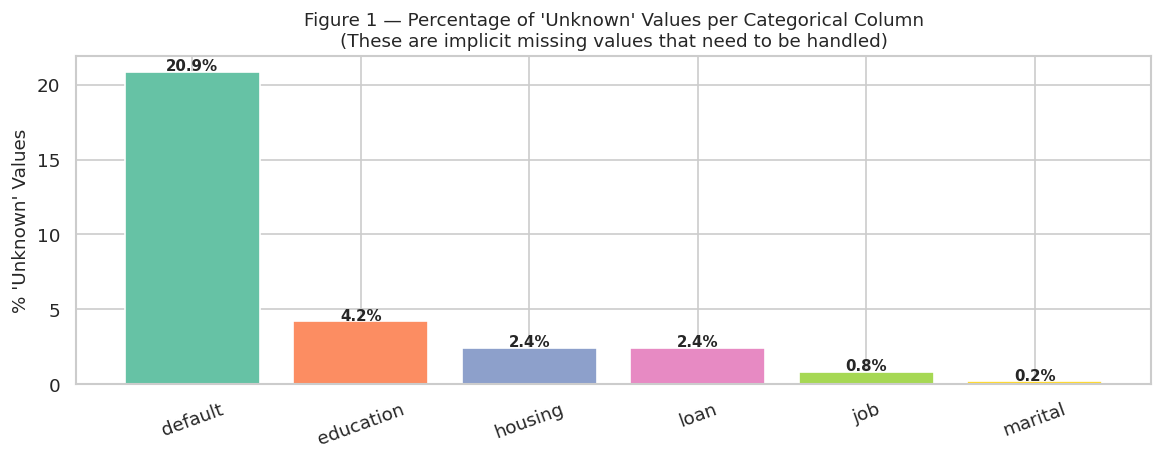


💡 INTERPRETATION: The 'default' column has the most unknowns (~21%).
   This means the bank didn't know if 1 in 5 clients had a credit default.
   Strategy: Encode 'unknown' as a separate category, or use imputation.


In [ ]:
#
# WHY THIS STEP?
# Real-world data is almost always imperfect. We need to check for:
#
# 1. EXPLICIT MISSING VALUES (NaN / NULL):
#    These are cells where no value was recorded at all.
#    Like an empty cell in Excel. Python represents them as "NaN"
#    (Not a Number). Most ML algorithms cannot handle NaN values.
#
# 2. IMPLICIT MISSING VALUES ("unknown"):
#    This dataset uses the text string "unknown" where data wasn't
#    available. These are NOT caught by isnull() — we have to search
#    for the string "unknown" manually. This is a sneaky form of
#    missing data that beginners often miss!
#
# 3. DUPLICATE ROWS:
#    Identical rows appearing more than once. Can bias the model by
#    giving extra weight to repeated examples.

print("\n" + "=" * 65)
print("  SECTION 3 — MISSING VALUES & DUPLICATES (Q9)")
print("=" * 65)

# --- Explicit NaN values ---
# isnull() returns True/False for each cell; .sum() counts the Trues per column
null_counts = df.isnull().sum()
total_nulls = null_counts.sum()
print(f"\n🔍 Explicit NaN (null) values:")
if total_nulls == 0:
    print("   ✅ None found — no explicit missing values in this dataset!")
else:
    print(null_counts[null_counts > 0])

# --- Implicit "unknown" string values ---
# We loop through each categorical column and count occurrences of "unknown"
print(f"\n🔍 Implicit 'unknown' string values (by column):")
unknown_counts = {}
for col in categorical_cols:
    count = (df[col] == 'unknown').sum()  # Count cells where value equals "unknown"
    if count > 0:
        unknown_counts[col] = count
        pct = count / len(df) * 100       # Convert to percentage of all rows
        print(f"   {col:20s} : {count:6,} values  ({pct:.1f}% of rows)")

total_unknown = sum(unknown_counts.values())
print(f"\n   Total 'unknown' values across all columns: {total_unknown:,}")
print(f"   That is {total_unknown/len(df)*100:.1f}% of all categorical data points")

# --- Duplicate rows ---
# duplicated() returns True for rows that are exact copies of a previous row
dup_count = df.duplicated().sum()
print(f"\n🔍 Duplicate rows: {dup_count:,}")
if dup_count > 0:
    print(f"   ⚠️  {dup_count} duplicate rows found — should be removed before modelling")
else:
    print("   ✅ No duplicates found")

# --- VISUALISE the "unknown" proportions ---
# A bar chart makes it much easier to see which columns have the most unknowns

fig, ax = plt.subplots(figsize=(10, 4))

# Sort by highest to lowest percentage for easier reading
unknown_series = pd.Series({
    k: v / len(df) * 100 for k, v in unknown_counts.items()
}).sort_values(ascending=False)

# Draw the bar chart
bars = ax.bar(unknown_series.index,
              unknown_series.values,
              color=sns.color_palette("Set2", len(unknown_series)))

# Add percentage labels on top of each bar
for bar, val in zip(bars, unknown_series.values):
    ax.text(bar.get_x() + bar.get_width() / 2,   # x position = centre of bar
            bar.get_height() + 0.1,                # y position = just above bar
            f'{val:.1f}%',                         # The label text
            ha='center', fontsize=9, fontweight='bold')

ax.set_ylabel("% 'Unknown' Values", fontsize=11)
ax.set_title("Figure 1 — Percentage of 'Unknown' Values per Categorical Column\n"
             "(These are implicit missing values that need to be handled)", fontsize=11)
ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig("/tmp/real_fig1_missing_unknown.png", dpi=120, bbox_inches='tight')
plt.show()
print("\n💡 INTERPRETATION: The 'default' column has the most unknowns (~21%).")
print("   This means the bank didn't know if 1 in 5 clients had a credit default.")
print("   Strategy: Encode 'unknown' as a separate category, or use imputation.")


---
## Cell 6: TARGET VARIABLE DISTRIBUTION



  SECTION 4 — TARGET VARIABLE DISTRIBUTION

📊 Subscription counts:
   'no'  (did NOT subscribe) : 36,548  (88.7%)
   'yes' (DID subscribe)     : 4,640  (11.3%)

⚠️  Class Imbalance Ratio — no:yes ≈ 7.9 : 1
   For every 1 subscriber, there are ~8 non-subscribers
   This MUST be handled before training any ML model


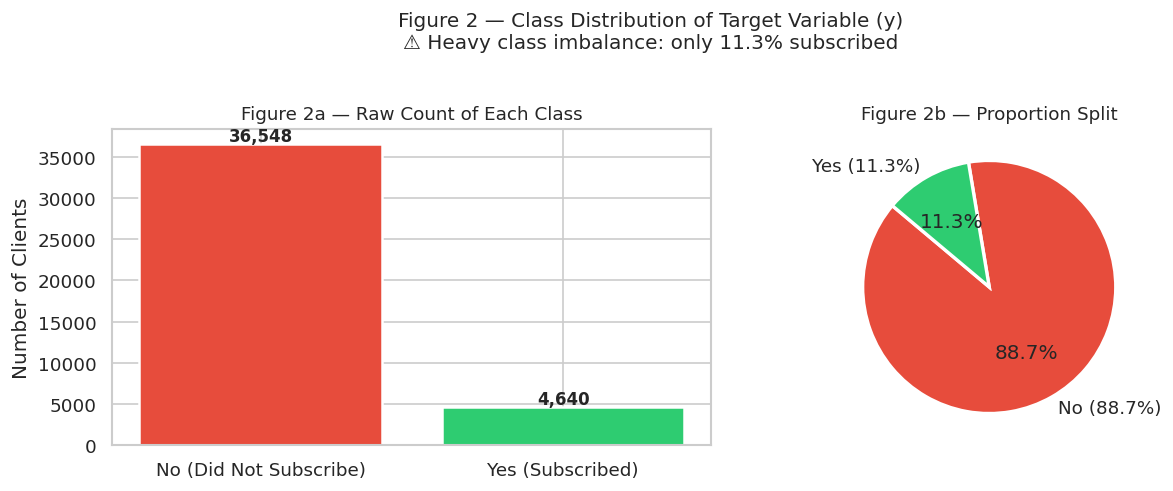

In [ ]:
#
# WHY THIS STEP?
# The "target variable" is what we're trying to predict — in this case,
# column 'y': did the client subscribe to a term deposit? (yes/no)
#
# CLASS IMBALANCE explained in plain English:
# Imagine you had 100 emails and only 11 were spam.
# If a model just predicted "not spam" for EVERY email, it would be
# 89% accurate — but completely useless for catching spam!
# The same problem applies here: only ~11% of clients subscribed.
# A naive model that always predicts "no" would be 89% accurate
# but would never identify a single potential subscriber.
# This is called "class imbalance" and must be addressed.

print("\n" + "=" * 65)
print("  SECTION 4 — TARGET VARIABLE DISTRIBUTION")
print("=" * 65)

# Count how many "yes" and "no" values exist
target_counts = df['y'].value_counts()
pct_yes = target_counts['yes'] / len(df) * 100
pct_no  = target_counts['no']  / len(df) * 100

print(f"\n📊 Subscription counts:")
print(f"   'no'  (did NOT subscribe) : {target_counts['no']:,}  ({pct_no:.1f}%)")
print(f"   'yes' (DID subscribe)     : {target_counts['yes']:,}  ({pct_yes:.1f}%)")
print(f"\n⚠️  Class Imbalance Ratio — no:yes ≈ {pct_no/pct_yes:.1f} : 1")
print(f"   For every 1 subscriber, there are ~{pct_no/pct_yes:.0f} non-subscribers")
print(f"   This MUST be handled before training any ML model")

# Create a 2-panel chart: bar chart + pie chart
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = ['#e74c3c', '#2ecc71']   # Red for "no", green for "yes"

# Panel 1: Bar chart showing raw counts
axes[0].bar(['No (Did Not Subscribe)', 'Yes (Subscribed)'],
            target_counts.values, color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_title("Figure 2a — Raw Count of Each Class", fontsize=11)
axes[0].set_ylabel("Number of Clients")
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 300, f'{v:,}', ha='center', fontweight='bold', fontsize=10)

# Panel 2: Pie chart showing proportions
axes[1].pie(target_counts.values,
            labels=[f'No ({pct_no:.1f}%)', f'Yes ({pct_yes:.1f}%)'],
            colors=colors, autopct='%1.1f%%', startangle=140,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title("Figure 2b — Proportion Split", fontsize=11)

plt.suptitle("Figure 2 — Class Distribution of Target Variable (y)\n"
             "⚠️ Heavy class imbalance: only 11.3% subscribed",
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("/tmp/real_fig2_target_distribution.png", dpi=120, bbox_inches='tight')
plt.show()


---
## Cell 7: NUMERIC FEATURE DISTRIBUTIONS (Q3)



  SECTION 5 — NUMERIC FEATURE DISTRIBUTIONS (Q3)


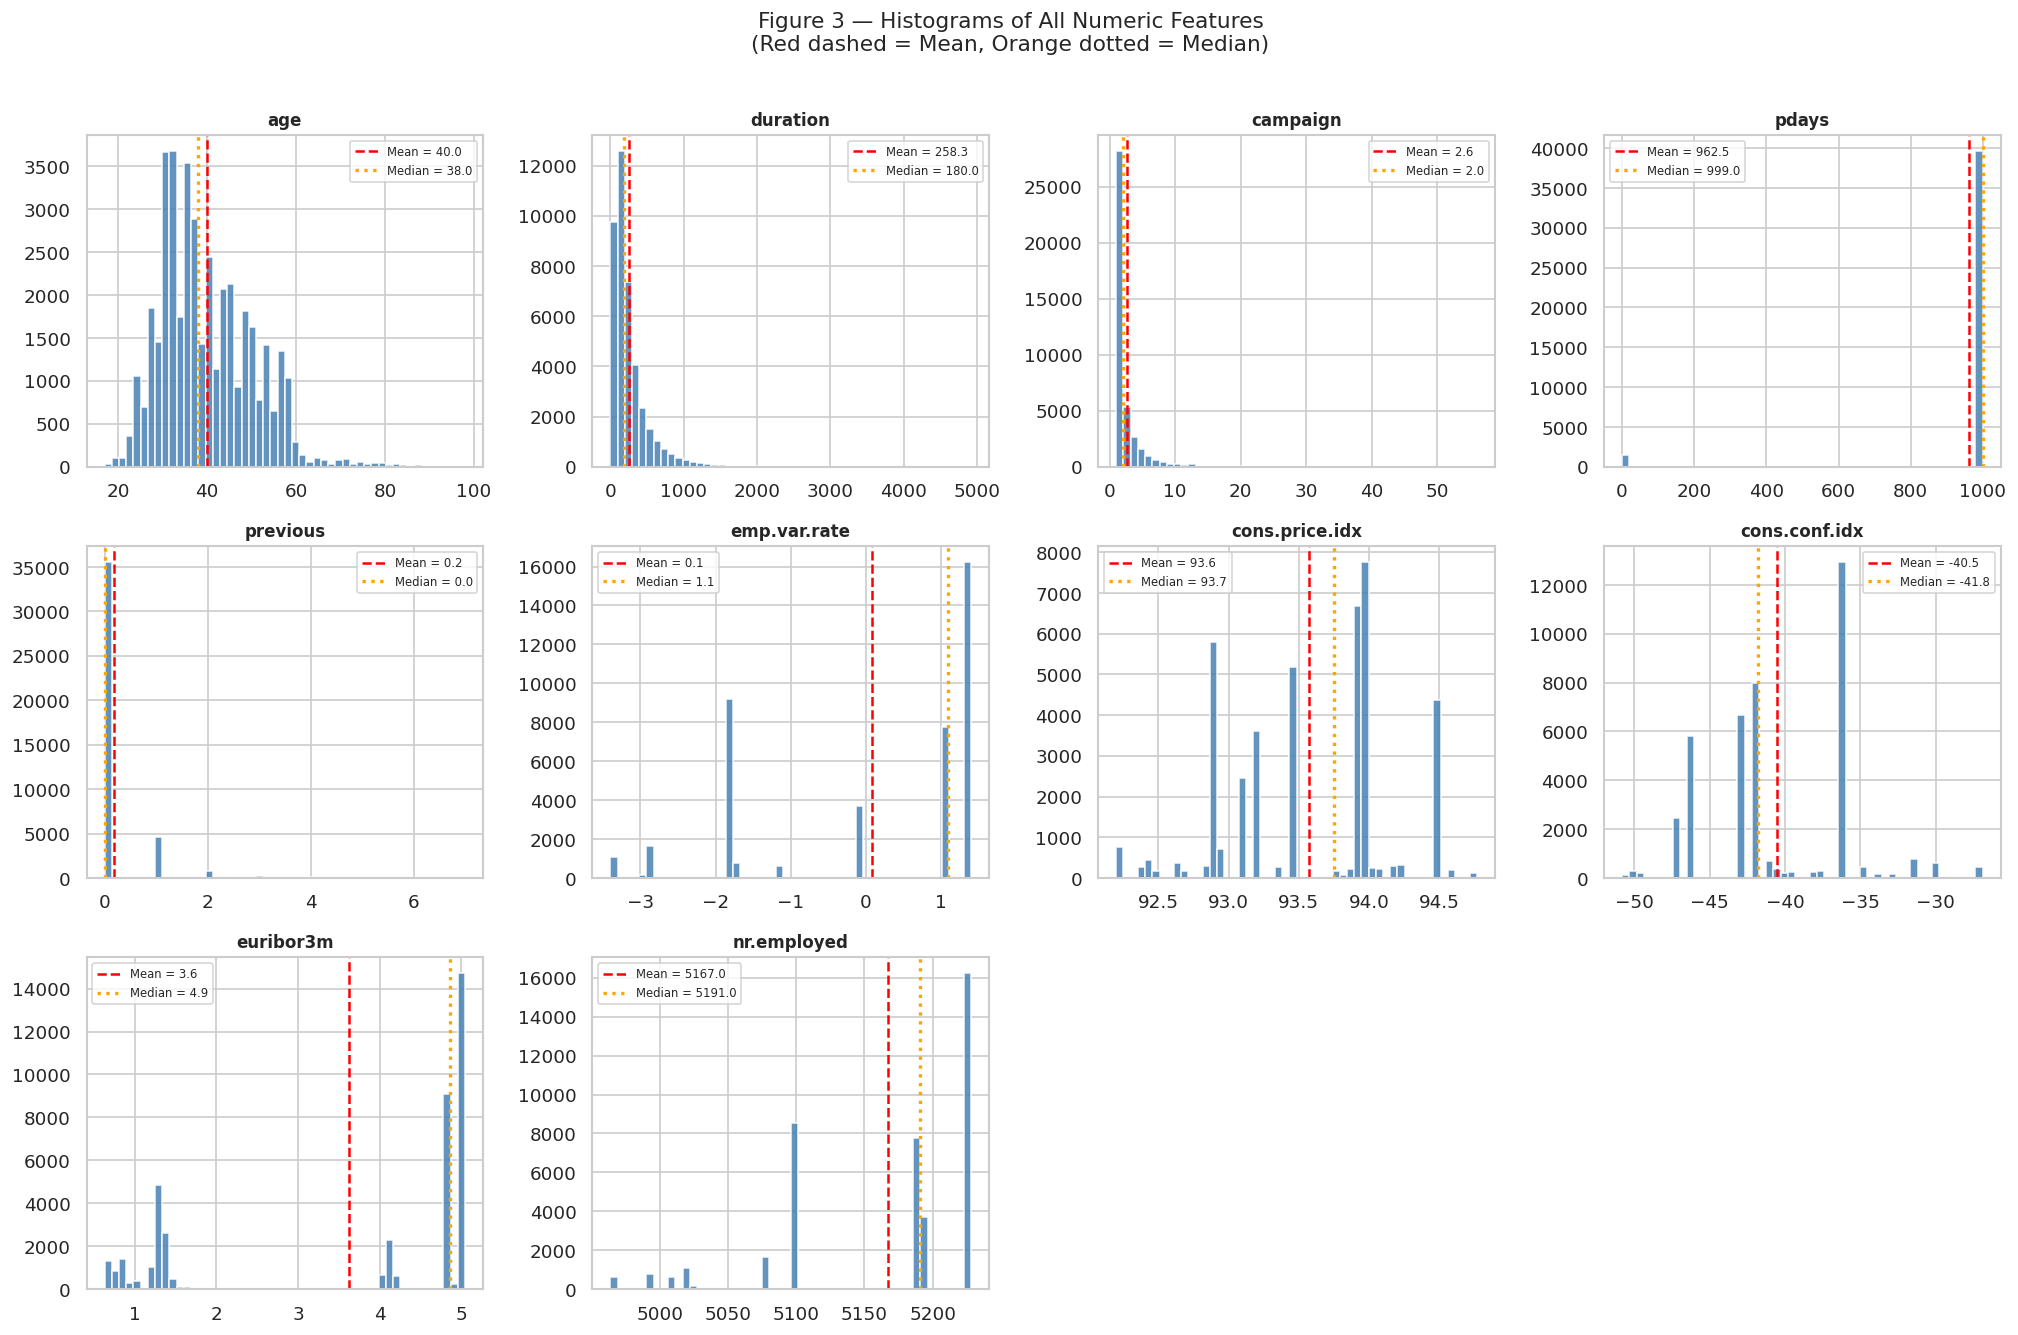


💡 KEY OBSERVATIONS:
   • 'duration' is heavily right-skewed — most calls are short, few are very long
   • 'pdays' has a huge spike at 999 (= 'client was never previously contacted')
   • 'campaign' is right-skewed — most clients contacted 1-3 times
   • Macro vars (emp.var.rate, euribor3m, nr.employed) show two-hump patterns
     → Reflecting the pre- and post-2008 financial crisis economic regimes


In [ ]:
#
# WHY THIS STEP?
# A histogram shows how values in a column are distributed.
# The X-axis shows the range of values; the Y-axis shows how many
# records fall in each "bin" (bucket) of that range.
#
# WHAT TO LOOK FOR:
# - Bell curve (normal)     → Values are evenly spread around the middle
# - Right skew              → Most values are low, but a few are very high
#                             (the tail extends to the RIGHT)
# - Left skew               → Most values are high, few are very low
# - Bimodal (two humps)     → Two distinct groups exist in the data
# - Spike at one value      → Many records share the exact same value
#                             (e.g., pdays has a huge spike at 999)
#
# The RED dashed line = MEAN (average)
# The ORANGE dotted line = MEDIAN (middle value)
# If mean ≠ median → the distribution is skewed

print("\n" + "=" * 65)
print("  SECTION 5 — NUMERIC FEATURE DISTRIBUTIONS (Q3)")
print("=" * 65)

# Create a grid of histograms — one per numeric column
# We use 3 rows × 4 columns = 12 subplots (we have 10 numeric features)
fig, axes = plt.subplots(3, 4, figsize=(17, 11))
axes = axes.flatten()   # Convert 2D grid into a 1D list for easy looping

for i, col in enumerate(numeric_cols):
    ax = axes[i]

    # Draw the histogram
    # bins=50 → divide the data range into 50 buckets
    # alpha=0.85 → slight transparency so bars look cleaner
    ax.hist(df[col].dropna(), bins=50, color='steelblue',
            edgecolor='white', alpha=0.85)

    # Add a vertical line for the MEAN
    mean_val   = df[col].mean()
    median_val = df[col].median()
    ax.axvline(mean_val,   color='red',    linestyle='--', lw=1.5,
               label=f'Mean = {mean_val:.1f}')
    ax.axvline(median_val, color='orange', linestyle=':',  lw=2.0,
               label=f'Median = {median_val:.1f}')

    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.legend(fontsize=7)
    ax.set_xlabel("")

# Hide the 2 unused subplot panels (we have 10 cols but 12 grid spots)
for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Figure 3 — Histograms of All Numeric Features\n"
             "(Red dashed = Mean, Orange dotted = Median)", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("/tmp/real_fig3_histograms.png", dpi=120, bbox_inches='tight')
plt.show()

print("\n💡 KEY OBSERVATIONS:")
print("   • 'duration' is heavily right-skewed — most calls are short, few are very long")
print("   • 'pdays' has a huge spike at 999 (= 'client was never previously contacted')")
print("   • 'campaign' is right-skewed — most clients contacted 1-3 times")
print("   • Macro vars (emp.var.rate, euribor3m, nr.employed) show two-hump patterns")
print("     → Reflecting the pre- and post-2008 financial crisis economic regimes")


---
## Cell 8: OUTLIER DETECTION (Q4)



  SECTION 6 — OUTLIER DETECTION — IQR METHOD (Q4)

Feature                     Outlier Count    % of Rows  Notes
----------------------------------------------------------------------
   age                           469         1.14%   Moderate
   duration                    2,963         7.19%   ⚠️ High
   campaign                    2,406         5.84%   ⚠️ High
   pdays                       1,515         3.68%   Moderate
   previous                    5,625        13.66%   ⚠️ High
   emp.var.rate                    0         0.00%   ✅ Low
   cons.price.idx                  0         0.00%   ✅ Low
   cons.conf.idx                 447         1.09%   Moderate
   euribor3m                       0         0.00%   ✅ Low
   nr.employed                     0         0.00%   ✅ Low


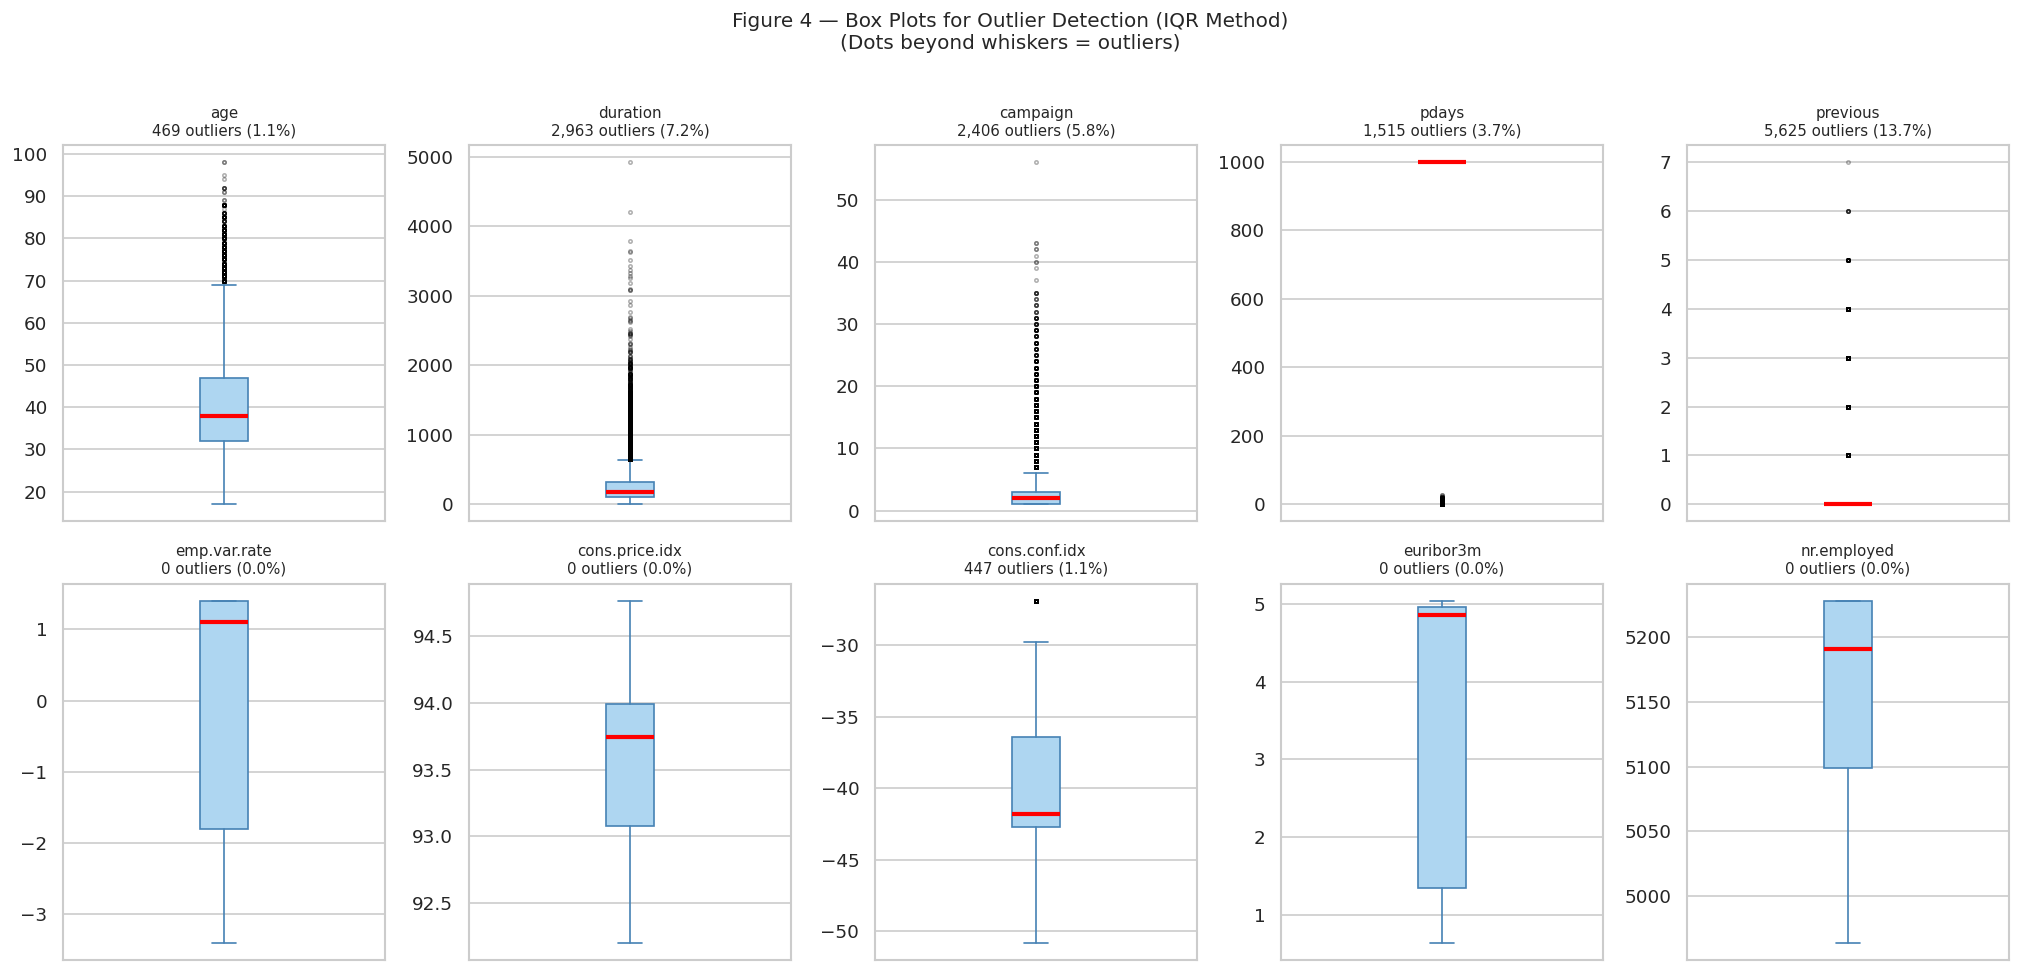


💡 KEY OBSERVATIONS:
   • 'campaign': Some clients contacted 30-50+ times — extreme outliers
   • 'duration': A few calls lasted over 4,000 seconds (~67 minutes)
   • 'pdays': The 999 spike is by design (= never contacted), not a real outlier
   • Economic indicators: Outliers likely reflect 2008 financial crisis extremes
     → These should be KEPT (real events), not removed


In [ ]:
#
# WHAT IS AN OUTLIER?
# An outlier is a value that is unusually far from the rest of the data.
# Example: if most clients are contacted 1-3 times but one client was
# contacted 56 times — that 56 is an outlier.
#
# WHY DO OUTLIERS MATTER IN ML?
# Outliers can distort model training. A linear regression model, for
# example, will bend its line to accommodate extreme values even if
# they're rare data entry errors.
#
# THE IQR METHOD (Interquartile Range):
# This is the most common way to detect outliers. Here's the logic:
#   - Q1 = 25th percentile (bottom quarter boundary)
#   - Q3 = 75th percentile (top quarter boundary)
#   - IQR = Q3 - Q1 (the "middle 50%" spread)
#   - Lower fence = Q1 - 1.5 × IQR  (anything below = outlier)
#   - Upper fence = Q3 + 1.5 × IQR  (anything above = outlier)
#
# BOX PLOT EXPLAINED:
# The box shows the middle 50% of data (Q1 to Q3).
# The line inside the box = median.
# The "whiskers" extend to the fences.
# Individual dots beyond the whiskers = outliers.

print("\n" + "=" * 65)
print("  SECTION 6 — OUTLIER DETECTION — IQR METHOD (Q4)")
print("=" * 65)

# Calculate and print outlier counts for each numeric column
outlier_summary = {}
print(f"\n{'Feature':<25} {'Outlier Count':>15} {'% of Rows':>12}  Notes")
print("-" * 70)
for col in numeric_cols:
    q1  = df[col].quantile(0.25)   # 25th percentile
    q3  = df[col].quantile(0.75)   # 75th percentile
    iqr = q3 - q1                  # Interquartile range
    lower_fence = q1 - 1.5 * iqr  # Values below this = outliers
    upper_fence = q3 + 1.5 * iqr  # Values above this = outliers

    # Count how many values fall outside the fences
    n_outliers = ((df[col] < lower_fence) | (df[col] > upper_fence)).sum()
    outlier_summary[col] = n_outliers
    pct = n_outliers / len(df) * 100
    note = "⚠️ High" if pct > 5 else ("✅ Low" if pct < 1 else "Moderate")
    print(f"   {col:<22} {n_outliers:>10,}     {pct:>8.2f}%   {note}")

# Draw box plots — one per numeric column
fig, axes = plt.subplots(2, 5, figsize=(17, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    ax = axes[i]
    # patch_artist=True → fills the box with colour (otherwise just an outline)
    bp = ax.boxplot(
        df[col].dropna(), vert=True, patch_artist=True,
        boxprops=dict(facecolor='#AED6F1', color='steelblue'),
        medianprops=dict(color='red', linewidth=2.5),  # Red line = median
        whiskerprops=dict(color='steelblue'),
        capprops=dict(color='steelblue'),
        flierprops=dict(marker='o', markersize=2, alpha=0.3, color='grey')
        # "fliers" = the dots beyond the whiskers = outliers
    )
    n_out = outlier_summary[col]
    pct   = n_out / len(df) * 100
    ax.set_title(f"{col}\n{n_out:,} outliers ({pct:.1f}%)", fontsize=9)
    ax.set_xticks([])   # Remove x-axis ticks (only one group per plot)

plt.suptitle("Figure 4 — Box Plots for Outlier Detection (IQR Method)\n"
             "(Dots beyond whiskers = outliers)", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("/tmp/real_fig4_boxplots.png", dpi=120, bbox_inches='tight')
plt.show()

print("\n💡 KEY OBSERVATIONS:")
print("   • 'campaign': Some clients contacted 30-50+ times — extreme outliers")
print("   • 'duration': A few calls lasted over 4,000 seconds (~67 minutes)")
print("   • 'pdays': The 999 spike is by design (= never contacted), not a real outlier")
print("   • Economic indicators: Outliers likely reflect 2008 financial crisis extremes")
print("     → These should be KEPT (real events), not removed")


---
## Cell 9: CORRELATION ANALYSIS (Q1)



  SECTION 7 — CORRELATION ANALYSIS (Q1)


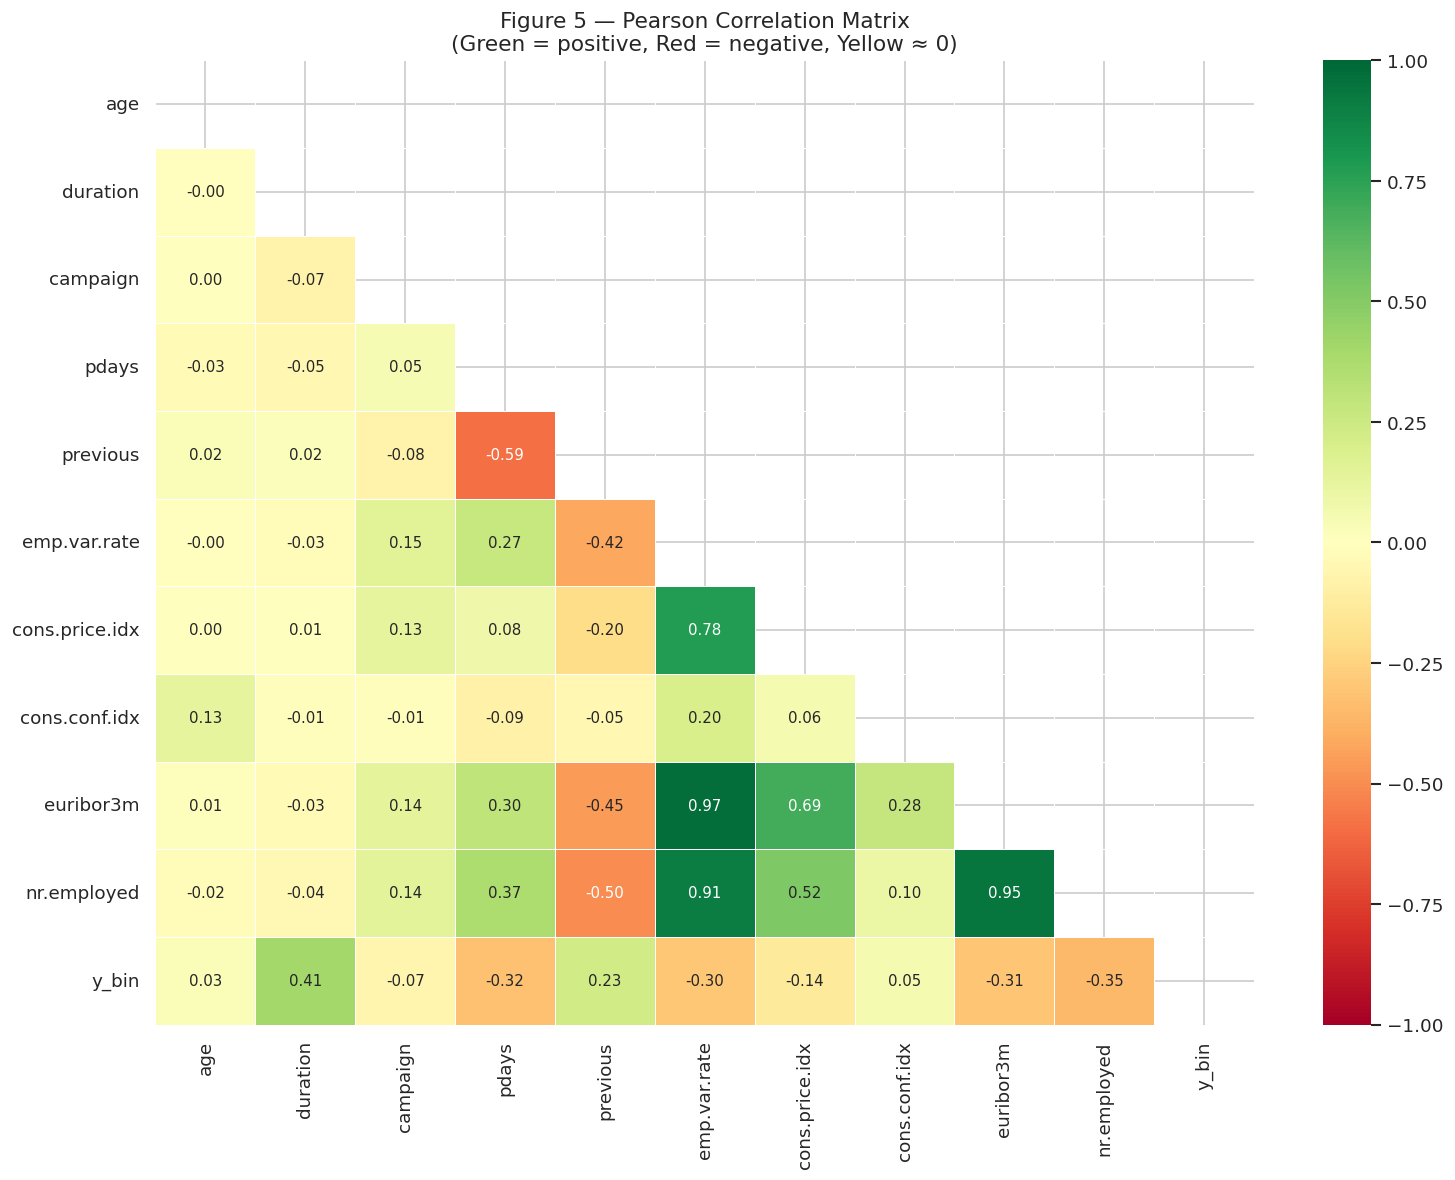


📊 Top Feature Correlations with Target (y_bin) — sorted by strength:
   (These are the features most predictive of subscription)

   duration               r = +0.4053  (↑ positive)
   nr.employed            r = -0.3547  (↓ negative)
   pdays                  r = -0.3249  (↓ negative)
   euribor3m              r = -0.3078  (↓ negative)
   emp.var.rate           r = -0.2983  (↓ negative)
   previous               r = +0.2302  (↑ positive)
   cons.price.idx         r = -0.1362  (↓ negative)
   campaign               r = -0.0664  (↓ negative)
   cons.conf.idx          r = +0.0549  (↑ positive)
   age                    r = +0.0304  (↑ positive)

⚠️  High Feature-to-Feature Correlations (|r| > 0.70) — Multicollinearity Risk:
   emp.var.rate ↔ euribor3m: r = 0.972  ← Consider removing one
   emp.var.rate ↔ nr.employed: r = 0.907  ← Consider removing one
   cons.price.idx ↔ emp.var.rate: r = 0.775  ← Consider removing one
   euribor3m ↔ nr.employed: r = 0.945  ← Consider removing one


In [ ]:
#
# WHAT IS CORRELATION?
# Correlation measures how closely two variables move together.
# Ranges from -1 to +1:
#   +1.0 = Perfect positive relationship (both go up together)
#    0.0 = No relationship at all
#   -1.0 = Perfect negative relationship (one goes up, other goes down)
#
# RULE OF THUMB for interpreting |r| (absolute value):
#   0.0 – 0.2 → Negligible / no relationship
#   0.2 – 0.4 → Weak relationship
#   0.4 – 0.6 → Moderate relationship
#   0.6 – 0.8 → Strong relationship
#   0.8 – 1.0 → Very strong / possible multicollinearity
#
# WHY MULTICOLLINEARITY IS A PROBLEM:
# If two features are highly correlated (e.g., r > 0.8), they carry
# almost the same information. Including both in a model wastes
# computation and can hurt model stability. One should be removed.
#
# THE HEATMAP:
# Each cell shows the correlation between two features.
# Green = positive correlation, Red = negative correlation.
# The diagonal is always 1.0 (each feature perfectly correlates with itself).
# We only show the lower triangle to avoid showing each pair twice.

print("\n" + "=" * 65)
print("  SECTION 7 — CORRELATION ANALYSIS (Q1)")
print("=" * 65)

# First, create a binary version of the target variable
# ML models work with numbers, not text — so "yes"→1 and "no"→0
df_enc = df.copy()   # Make a copy so we don't modify the original
df_enc['y_bin'] = (df_enc['y'] == 'yes').astype(int)
# (df_enc['y'] == 'yes') → creates True/False for each row
# .astype(int)           → converts True→1 and False→0

# Build correlation matrix including the binary target
corr_cols   = numeric_cols + ['y_bin']
corr_matrix = df_enc[corr_cols].corr()   # .corr() computes all pairwise correlations

# --- Heatmap ---
fig, ax = plt.subplots(figsize=(13, 10))

# Create a mask to hide the upper triangle (we only need lower triangle)
# np.triu = "upper triangle"; np.ones_like creates a same-shape matrix of 1s
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    annot=True,         # Show the correlation number in each cell
    fmt=".2f",          # Format numbers to 2 decimal places
    cmap="RdYlGn",      # Color scale: Red (negative) → Yellow (zero) → Green (positive)
    center=0,           # Zero correlation = yellow (middle of scale)
    mask=mask,          # Hide upper triangle
    linewidths=0.5,     # Thin lines between cells
    ax=ax,
    annot_kws={"size": 9},   # Font size for the numbers inside cells
    vmin=-1, vmax=1          # Colour scale from -1 to +1
)
ax.set_title("Figure 5 — Pearson Correlation Matrix\n"
             "(Green = positive, Red = negative, Yellow ≈ 0)", fontsize=13)
plt.tight_layout()
plt.savefig("/tmp/real_fig5_correlation_matrix.png", dpi=120, bbox_inches='tight')
plt.show()

# --- Print top correlations WITH the target ---
print("\n📊 Top Feature Correlations with Target (y_bin) — sorted by strength:")
print("   (These are the features most predictive of subscription)\n")
target_corr = (corr_matrix['y_bin']
               .drop('y_bin')           # Remove the target correlating with itself
               .abs()                   # Take absolute value (direction doesn't matter here)
               .sort_values(ascending=False))  # Highest first
for feat, val in target_corr.items():
    direction = "↑ positive" if corr_matrix.loc[feat, 'y_bin'] > 0 else "↓ negative"
    print(f"   {feat:<22} r = {corr_matrix.loc[feat,'y_bin']:+.4f}  ({direction})")

# --- Flag high feature-to-feature correlations ---
print(f"\n⚠️  High Feature-to-Feature Correlations (|r| > 0.70) — Multicollinearity Risk:")
found = False
for col1 in numeric_cols:
    for col2 in numeric_cols:
        if col1 < col2:   # Only check each pair once (not both directions)
            r = corr_matrix.loc[col1, col2]
            if abs(r) > 0.70:
                print(f"   {col1} ↔ {col2}: r = {r:.3f}  ← Consider removing one")
                found = True
if not found:
    print("   None found above 0.70 threshold")


---
## Cell 10: CATEGORICAL FEATURE DISTRIBUTIONS (Q6)



  SECTION 8 — CATEGORICAL FEATURE DISTRIBUTIONS (Q6)

   job            : 12 unique categories | most common = 'admin.' (25.3%)
   marital        : 4 unique categories | most common = 'married' (60.5%)
   education      : 8 unique categories | most common = 'university.degree' (29.5%)
   default        : 3 unique categories | most common = 'no' (79.1%)
   housing        : 3 unique categories | most common = 'yes' (52.4%)
   loan           : 3 unique categories | most common = 'no' (82.4%)
   contact        : 2 unique categories | most common = 'cellular' (63.5%)
   month          : 10 unique categories | most common = 'may' (33.4%)
   day_of_week    : 5 unique categories | most common = 'thu' (20.9%)
   poutcome       : 3 unique categories | most common = 'nonexistent' (86.3%)


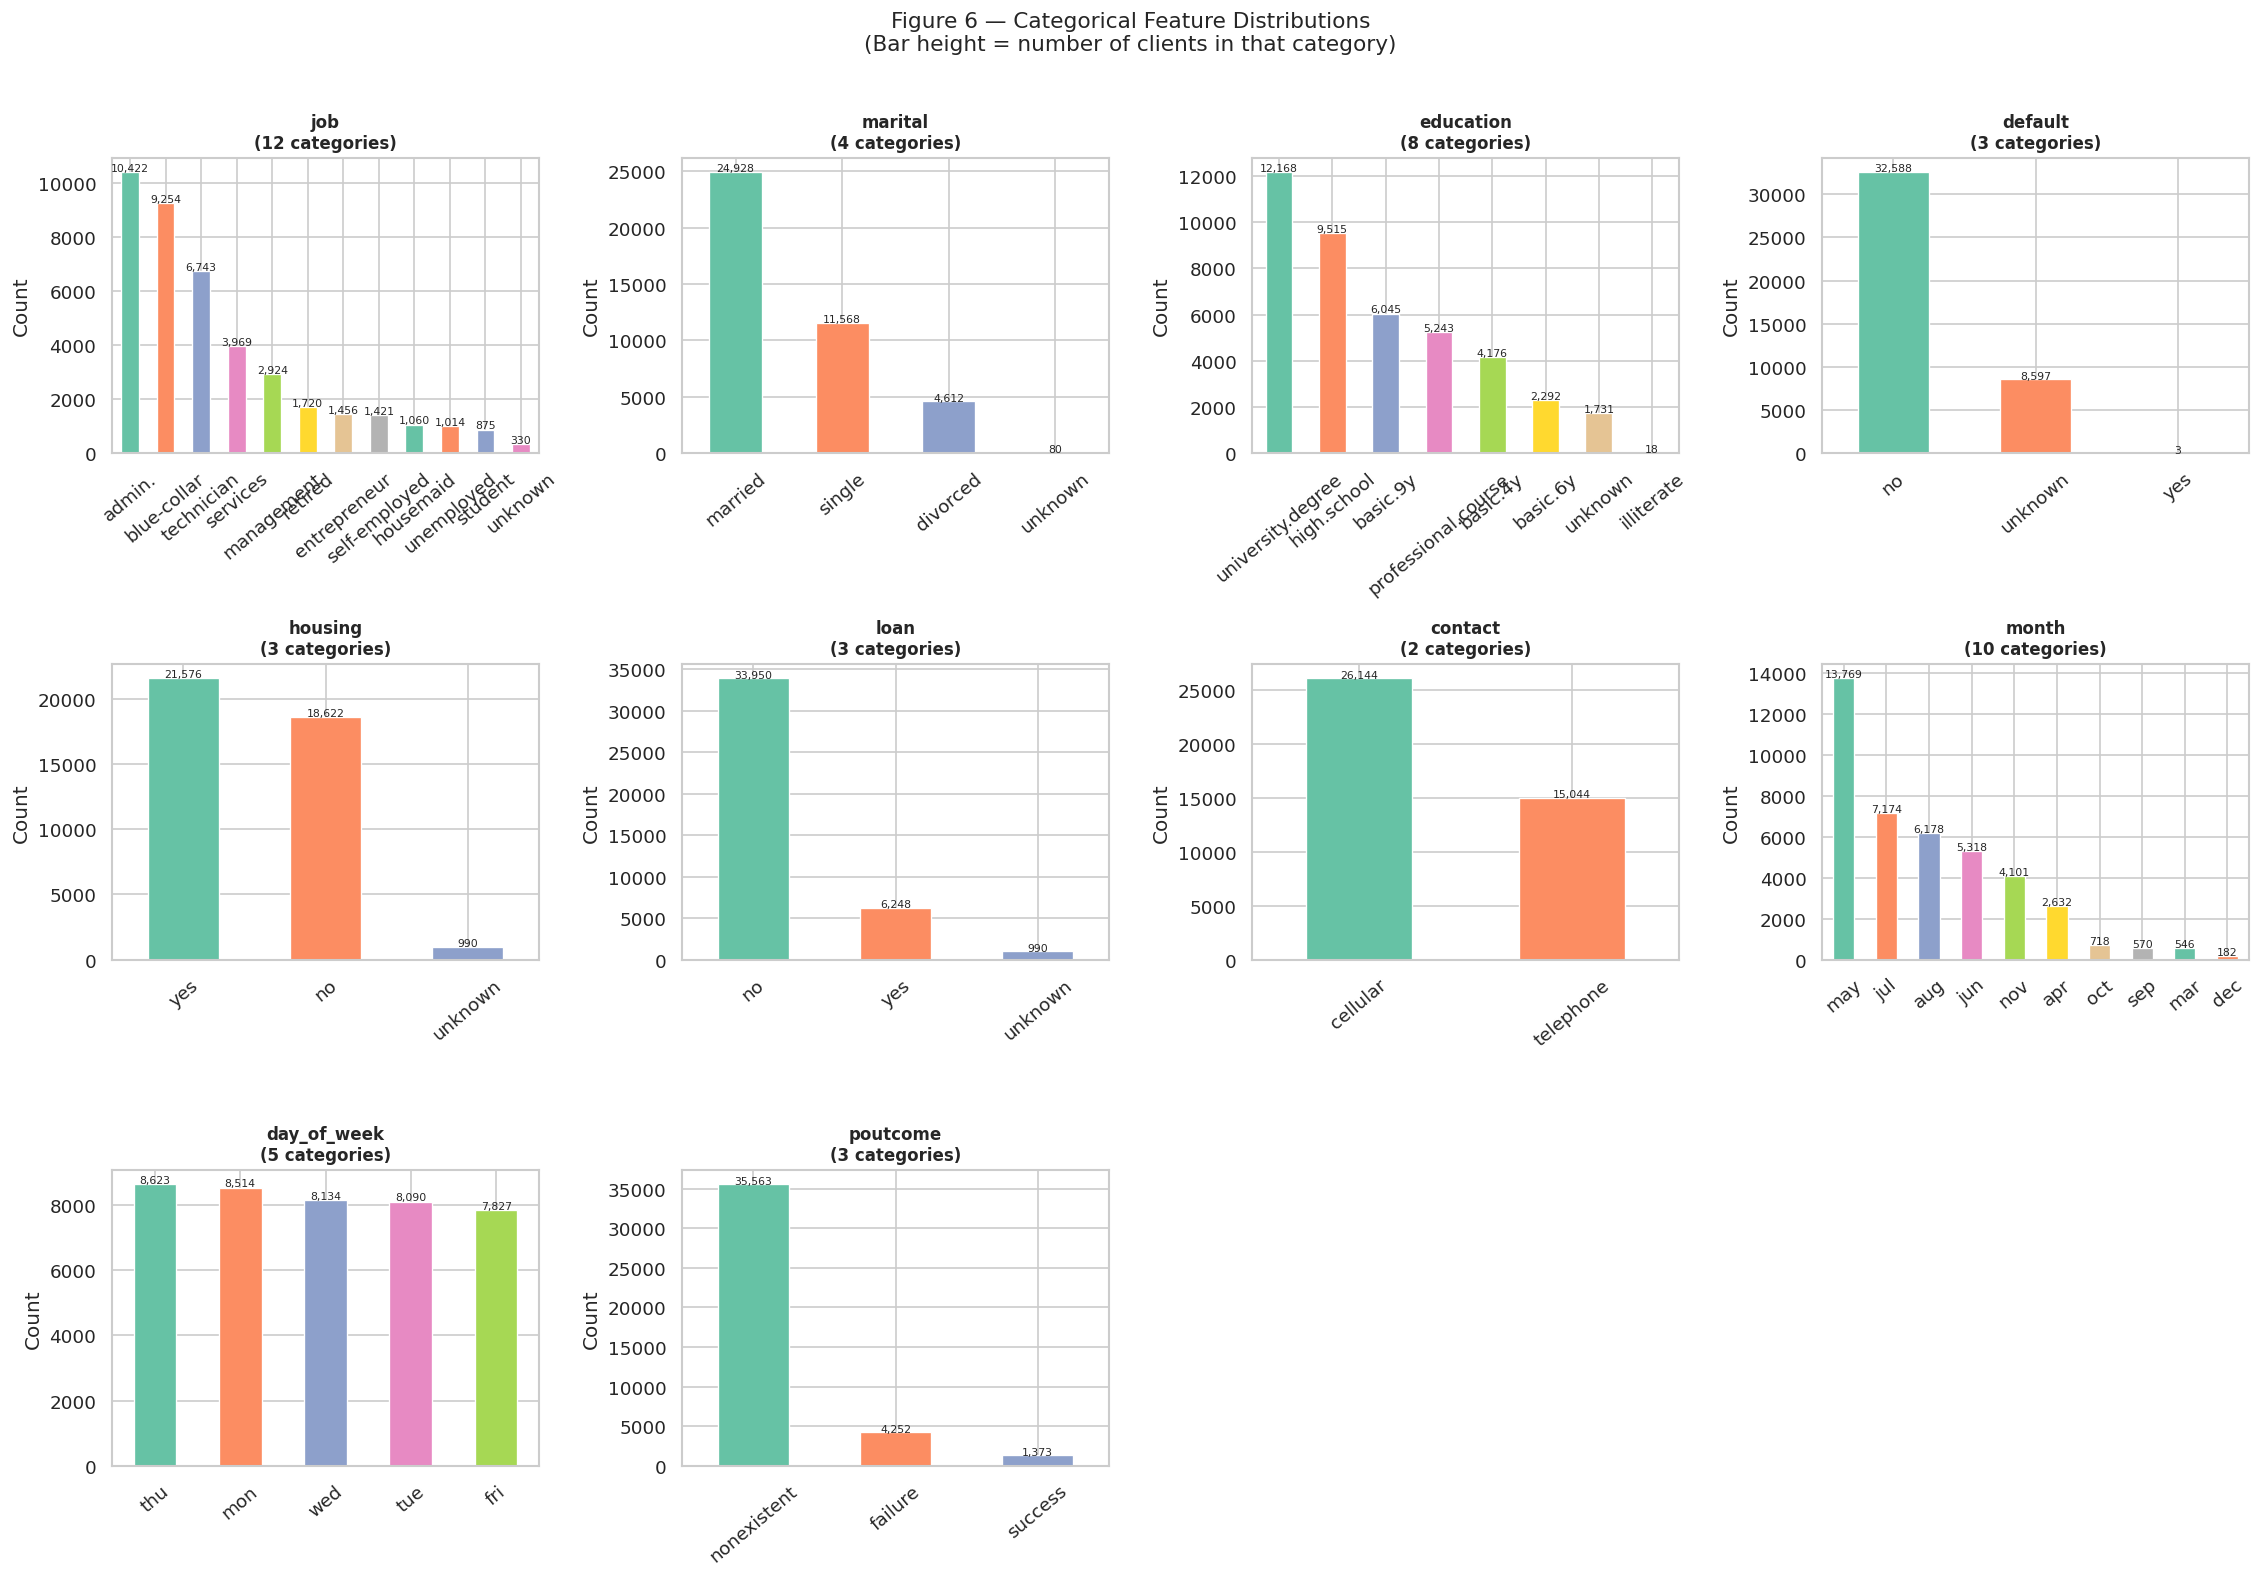


💡 KEY OBSERVATIONS:
   • 'job'      : 'admin.' and 'blue-collar' dominate (~25% + 22%)
   • 'marital'  : 'married' is ~61% of clients
   • 'month'    : May has the most contacts (~33%) — but lowest success rate!
   • 'poutcome' : ~96% 'nonexistent' — most never had a prior campaign
   • 'contact'  : Cellular (63%) outperforms telephone (37%) in success rate


In [ ]:
#
# WHY THIS STEP?
# Categorical features contain labels or groups rather than numbers.
# Examples: job = "admin.", "blue-collar"; month = "jan", "feb", etc.
#
# For categorical features we want to know:
# - How many unique categories exist? (too many = encoding challenge)
# - Is it balanced? (equal counts across categories = good)
#   or imbalanced? (one category dominates = potential bias)
# - Are any categories very rare? (< 1% of rows = might not help the model)
#
# WHAT ARE BAR CHARTS?
# Each bar represents one category. The bar's HEIGHT = how many records
# belong to that category. This makes it easy to spot dominant categories.

print("\n" + "=" * 65)
print("  SECTION 8 — CATEGORICAL FEATURE DISTRIBUTIONS (Q6)")
print("=" * 65)

# Print a quick text summary first
cat_no_target = [c for c in categorical_cols if c != 'y']
print()
for col in cat_no_target:
    vc = df[col].value_counts()
    top_cat = vc.index[0]
    top_pct = vc.iloc[0] / len(df) * 100
    print(f"   {col:<15}: {len(vc)} unique categories | most common = '{top_cat}' ({top_pct:.1f}%)")

# Create the bar charts — one per categorical column
fig, axes = plt.subplots(3, 4, figsize=(19, 13))
axes = axes.flatten()

for i, col in enumerate(cat_no_target):
    ax = axes[i]
    vc = df[col].value_counts()  # Count records per category, sorted highest→lowest

    # Different colour for each bar using seaborn's Set2 palette
    colors_list = sns.color_palette("Set2", len(vc))
    vc.plot(kind='bar', ax=ax, color=colors_list, edgecolor='white', linewidth=0.8)

    ax.set_title(f"{col}\n({len(vc)} categories)", fontsize=10, fontweight='bold')
    ax.tick_params(axis='x', rotation=40)
    ax.set_xlabel("")
    ax.set_ylabel("Count")

    # Add count labels on top of bars
    for bar in ax.patches:
        if bar.get_height() > 0:
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 50,
                    f'{int(bar.get_height()):,}',
                    ha='center', fontsize=6.5, rotation=0)

# Hide unused subplot panels
for j in range(len(cat_no_target), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Figure 6 — Categorical Feature Distributions\n"
             "(Bar height = number of clients in that category)", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("/tmp/real_fig6_categorical_distributions.png", dpi=120, bbox_inches='tight')
plt.show()

print("\n💡 KEY OBSERVATIONS:")
print("   • 'job'      : 'admin.' and 'blue-collar' dominate (~25% + 22%)")
print("   • 'marital'  : 'married' is ~61% of clients")
print("   • 'month'    : May has the most contacts (~33%) — but lowest success rate!")
print("   • 'poutcome' : ~96% 'nonexistent' — most never had a prior campaign")
print("   • 'contact'  : Cellular (63%) outperforms telephone (37%) in success rate")


---
## Cell 11: SUBSCRIPTION RATE BY CATEGORY (Q5 & Q7)



  SECTION 9 — SUBSCRIPTION RATE BY KEY CATEGORIES (Q5 & Q7)


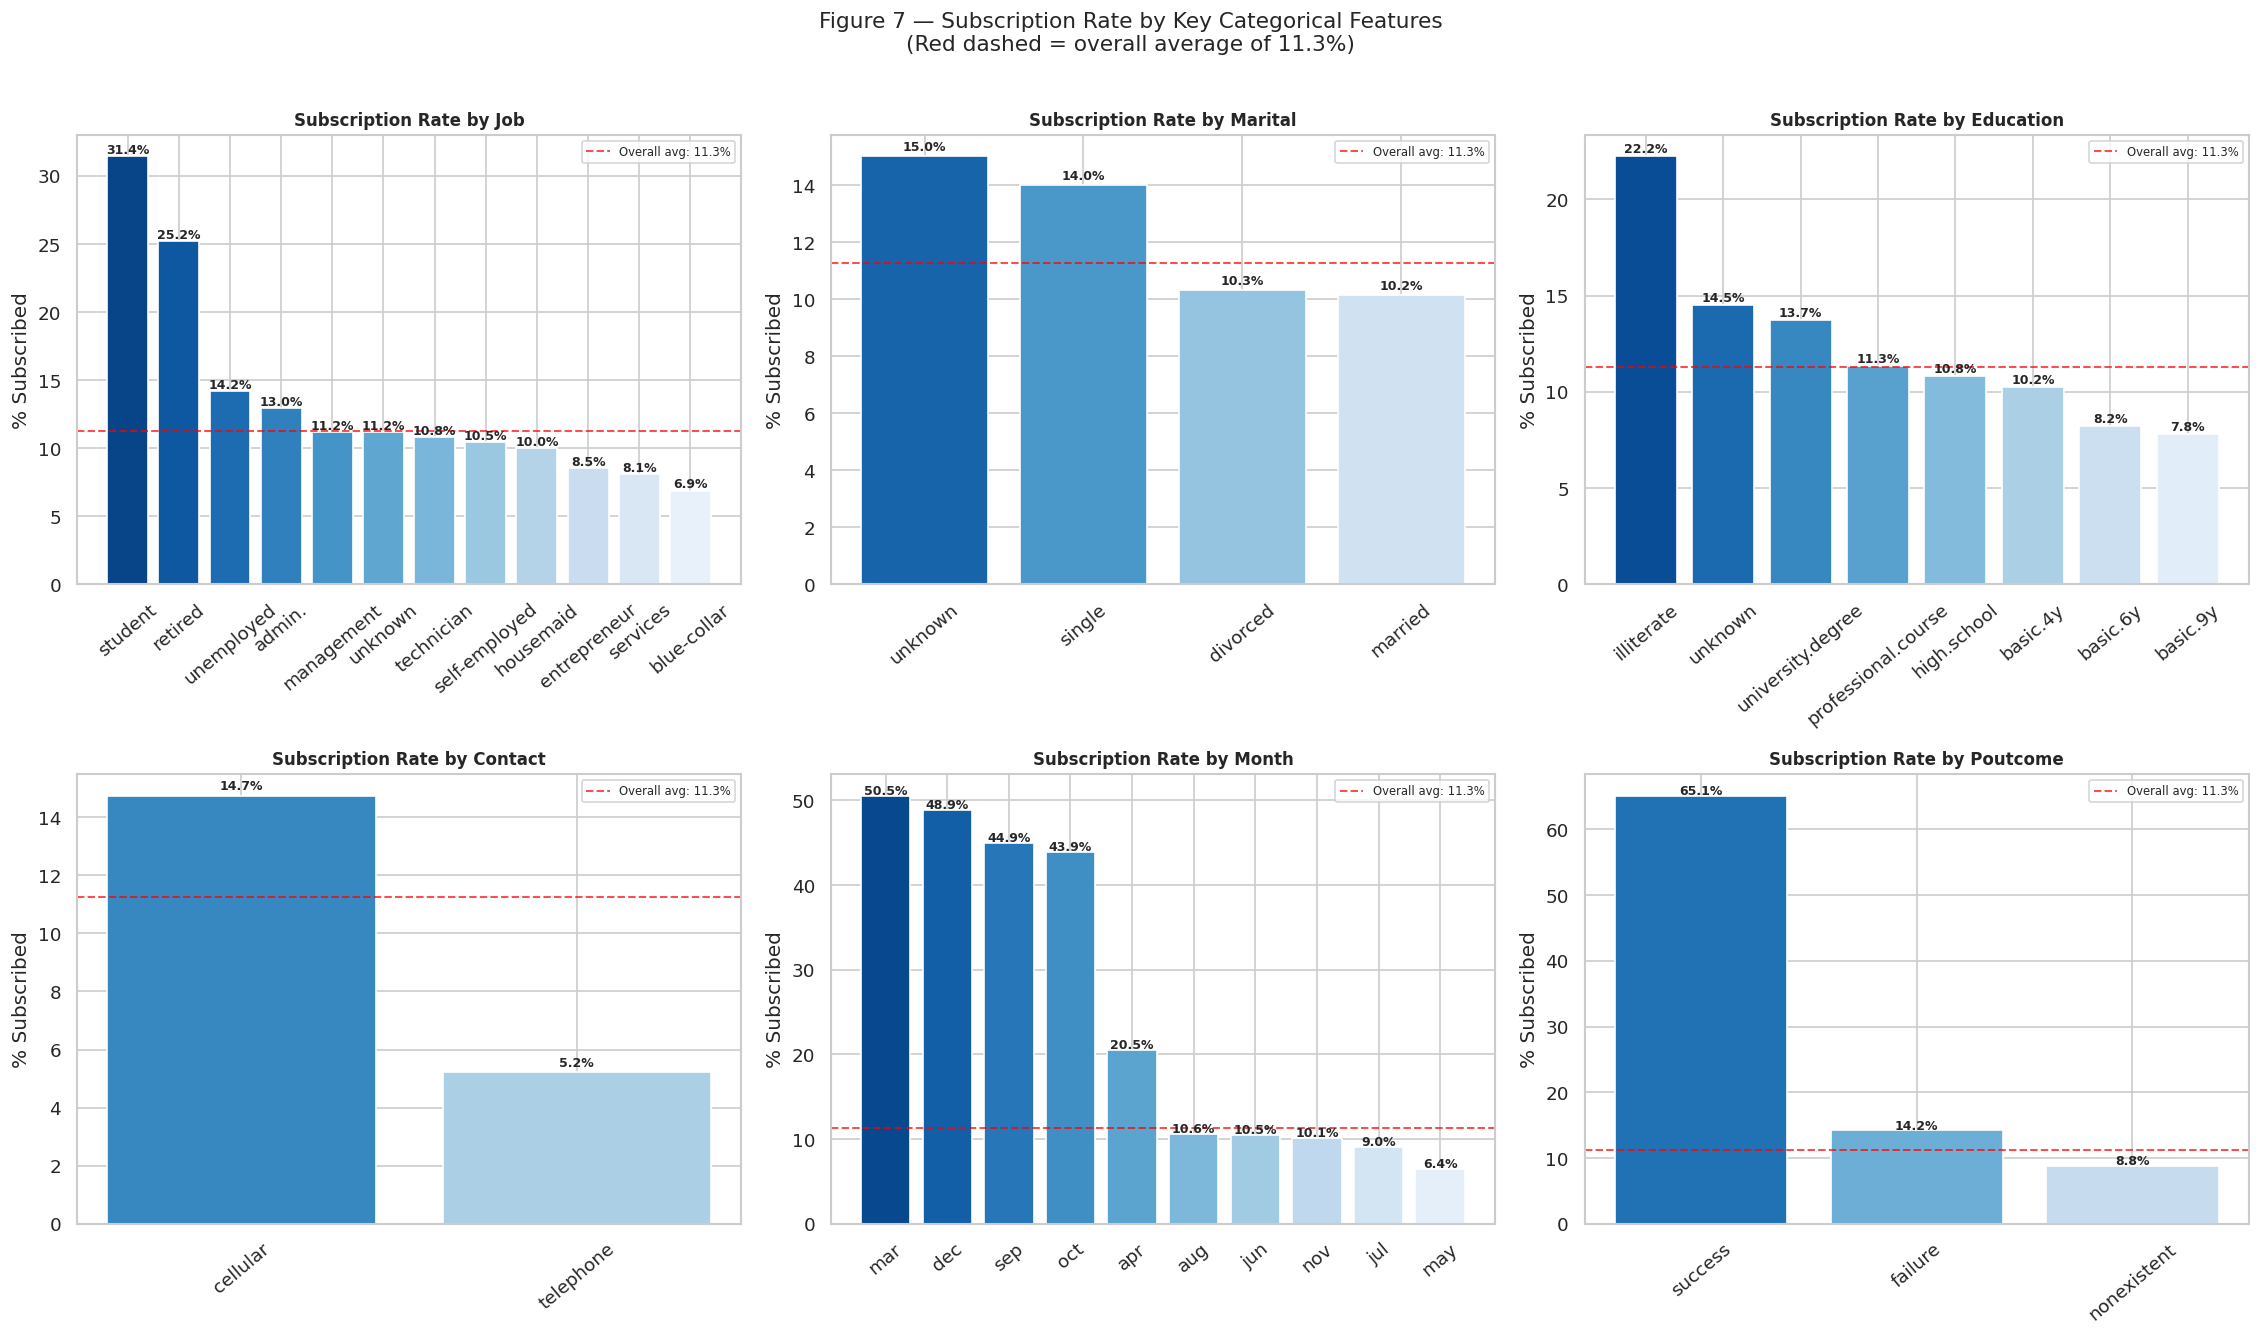


💡 KEY BUSINESS INSIGHTS:
   • 'poutcome = success' clients subscribe at ~65% — 6× the average!
   • Students and retired clients subscribe at higher rates than blue-collar
   • March, September, October, December are the best months to call
   • May has the most calls but one of the LOWEST success rates — rethink strategy!
   • Cellular contact is far more effective than telephone


In [ ]:
#
# WHY THIS STEP?
# Instead of just showing how many clients are in each category,
# we now ask: "Of the clients in each category, what % actually subscribed?"
#
# This reveals ACTIONABLE PATTERNS for the bank:
# - Which job types are most likely to subscribe?
# - Which months work best for calling?
# - Does having a previous campaign success predict future success?
#
# HOW WE CALCULATE SUBSCRIPTION RATE:
# For each category (e.g., job = "admin."), we:
#   1. Find all clients with that job
#   2. Count how many said "yes"
#   3. Divide by total clients with that job → that's the subscription rate

print("\n" + "=" * 65)
print("  SECTION 9 — SUBSCRIPTION RATE BY KEY CATEGORIES (Q5 & Q7)")
print("=" * 65)

# These 6 features are most interesting from a business perspective
key_cats = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']

fig, axes = plt.subplots(2, 3, figsize=(19, 11))
axes = axes.flatten()

for i, col in enumerate(key_cats):
    ax = axes[i]

    # Calculate subscription rate per category
    # groupby(col) → groups rows by this column's value
    # ['y'] → we care about the target column
    # .apply(lambda x: (x == 'yes').mean() * 100) → % that said yes
    sub_rate = (df.groupby(col)['y']
                .apply(lambda x: (x == 'yes').mean() * 100)
                .sort_values(ascending=False))

    # Colour bars: top performer = darkest blue
    palette = sns.color_palette("Blues_r", len(sub_rate))
    bars = ax.bar(sub_rate.index, sub_rate.values, color=palette, edgecolor='white')

    ax.set_title(f"Subscription Rate by {col.capitalize()}", fontsize=10, fontweight='bold')
    ax.set_ylabel("% Subscribed")
    ax.tick_params(axis='x', rotation=40)

    # Add % label on each bar
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.2,
                f'{bar.get_height():.1f}%',
                ha='center', fontsize=7.5, fontweight='bold')

    # Add a horizontal reference line showing the OVERALL subscription rate (~11.3%)
    ax.axhline(y=pct_yes, color='red', linestyle='--', lw=1.2, alpha=0.7,
               label=f'Overall avg: {pct_yes:.1f}%')
    ax.legend(fontsize=7)

plt.suptitle("Figure 7 — Subscription Rate by Key Categorical Features\n"
             "(Red dashed = overall average of 11.3%)", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("/tmp/real_fig7_subscription_by_category.png", dpi=120, bbox_inches='tight')
plt.show()

print("\n💡 KEY BUSINESS INSIGHTS:")
print("   • 'poutcome = success' clients subscribe at ~65% — 6× the average!")
print("   • Students and retired clients subscribe at higher rates than blue-collar")
print("   • March, September, October, December are the best months to call")
print("   • May has the most calls but one of the LOWEST success rates — rethink strategy!")
print("   • Cellular contact is far more effective than telephone")


---
## Cell 12: NUMERIC FEATURES vs TARGET (Q5)



  SECTION 10 — NUMERIC FEATURES vs TARGET VARIABLE (Q5)


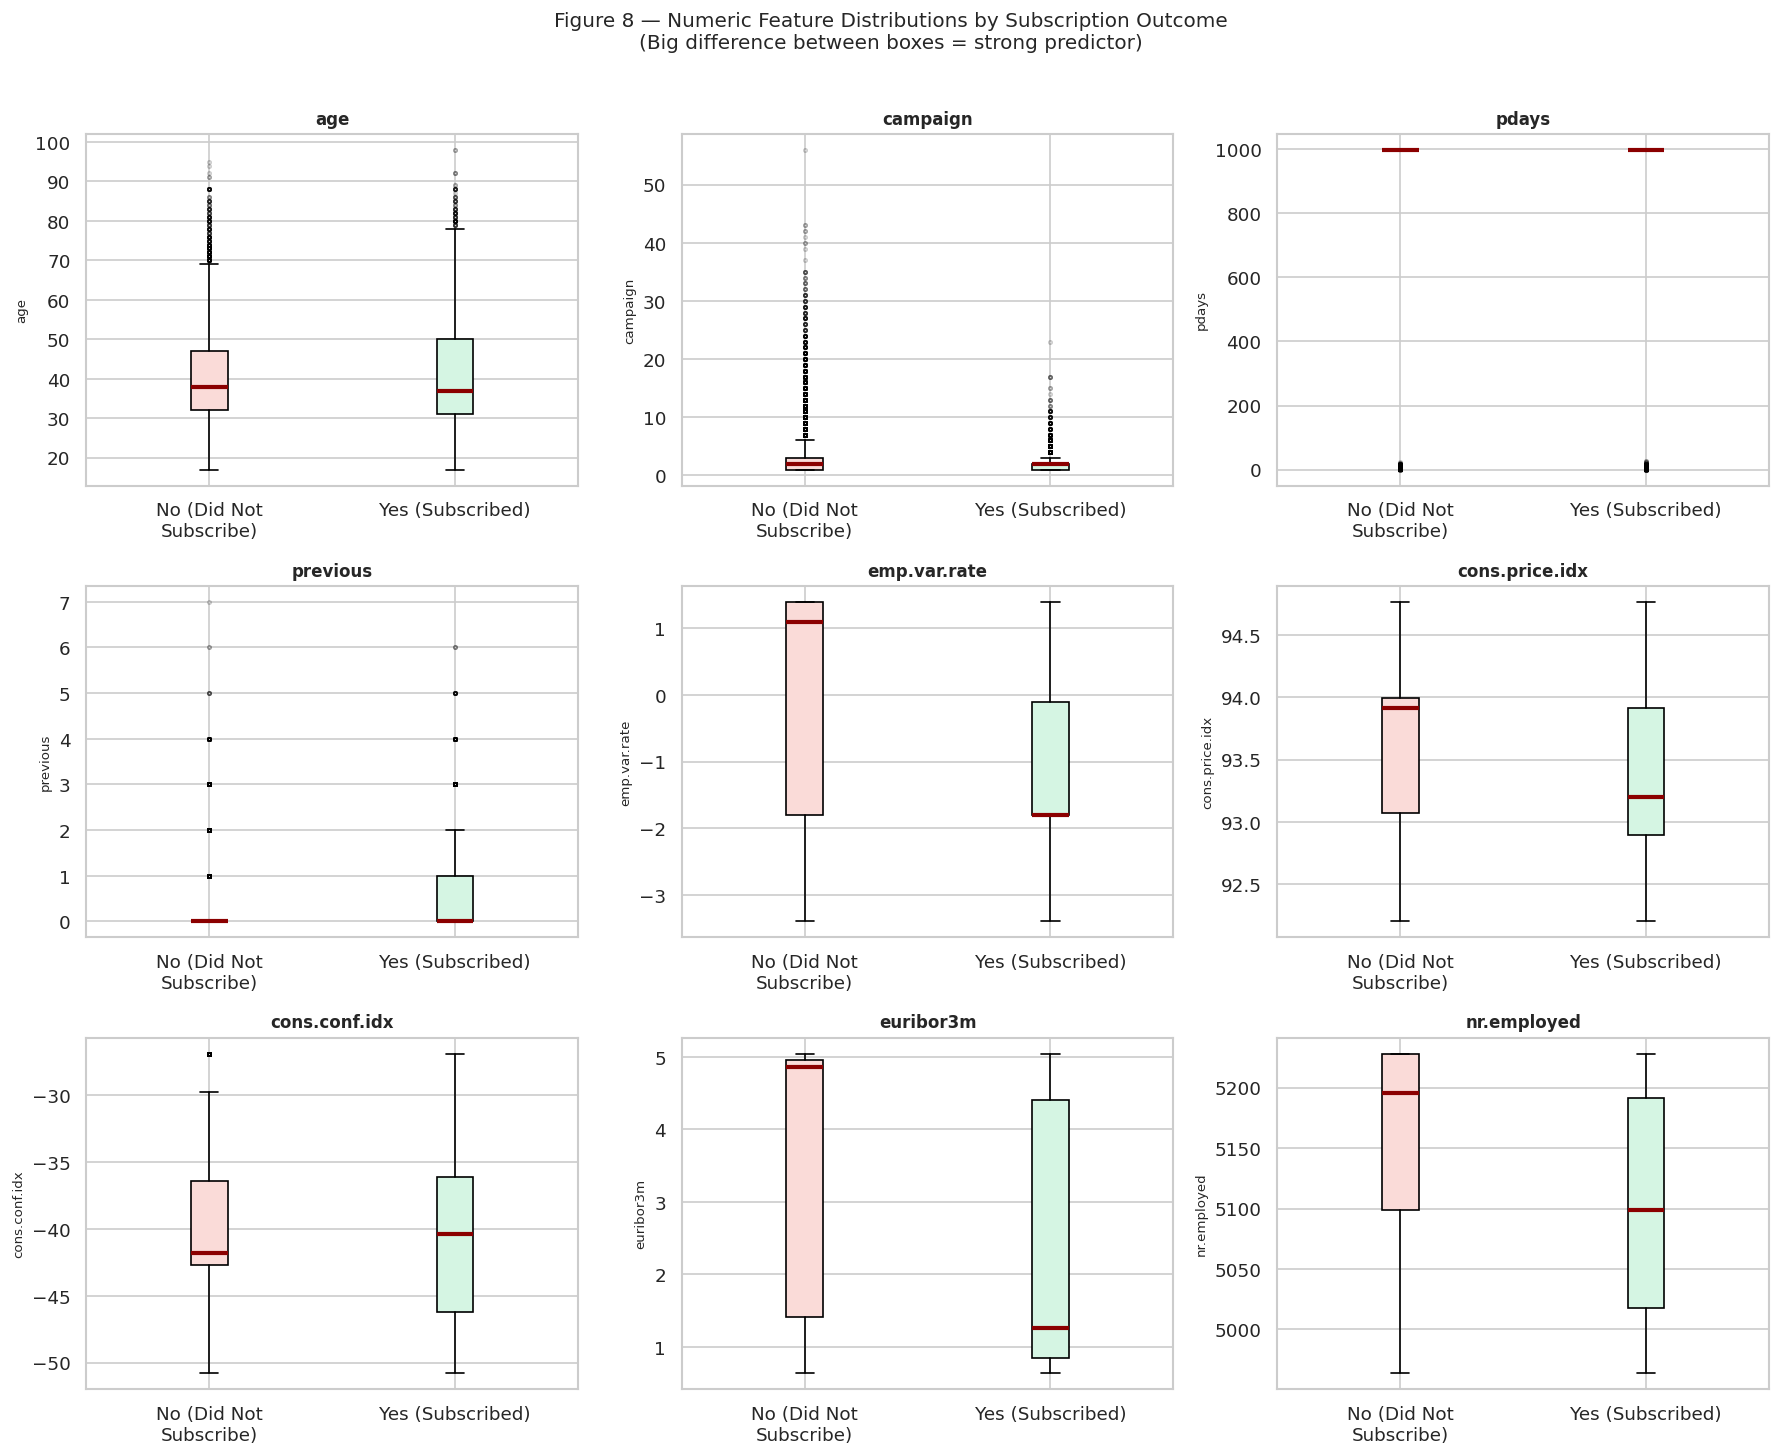


💡 KEY OBSERVATIONS:
   • 'nr.employed' and 'euribor3m': Subscribers tend to be called when
     employment is LOWER and interest rates are LOWER
     → Economic downturns drive people to seek secure investments
   • 'campaign': Non-subscribors were contacted MORE times — diminishing returns
   • 'pdays' and 'previous': Clients with prior contact history subscribe more


In [ ]:
#
# WHY THIS STEP?
# Here we compare how numeric features DIFFER between clients who
# subscribed (yes) vs those who didn't (no).
#
# We use SIDE-BY-SIDE BOX PLOTS — one box for "no", one for "yes".
# If the two boxes are at very different heights → that feature is
# a strong separator between the two groups → it's a useful predictor.
#
# If the boxes overlap almost completely → the feature doesn't help
# distinguish subscribors from non-subscribors.

print("\n" + "=" * 65)
print("  SECTION 10 — NUMERIC FEATURES vs TARGET VARIABLE (Q5)")
print("=" * 65)

key_numerics = ['age', 'campaign', 'pdays', 'previous',
                'emp.var.rate', 'cons.price.idx',
                'cons.conf.idx', 'euribor3m', 'nr.employed']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(key_numerics):
    ax = axes[i]

    # Separate the data into "no" and "yes" groups
    group_no  = df.loc[df['y'] == 'no',  col].dropna()
    group_yes = df.loc[df['y'] == 'yes', col].dropna()

    bp = ax.boxplot(
        [group_no, group_yes],
        labels=['No (Did Not\nSubscribe)', 'Yes (Subscribed)'],
        patch_artist=True,
        boxprops=dict(facecolor='lightcoral'),
        medianprops=dict(color='darkred', linewidth=2.5),
        flierprops=dict(marker='o', markersize=2, alpha=0.2)
    )

    # Colour boxes differently: red for "no", green for "yes"
    colors_bp = ['#FADBD8', '#D5F5E3']  # Light red, light green
    for patch, colour in zip(bp['boxes'], colors_bp):
        patch.set_facecolor(colour)

    ax.set_title(f"{col}", fontsize=10, fontweight='bold')
    ax.set_ylabel(col, fontsize=8)

plt.suptitle("Figure 8 — Numeric Feature Distributions by Subscription Outcome\n"
             "(Big difference between boxes = strong predictor)", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("/tmp/real_fig8_numeric_vs_target.png", dpi=120, bbox_inches='tight')
plt.show()

print("\n💡 KEY OBSERVATIONS:")
print("   • 'nr.employed' and 'euribor3m': Subscribers tend to be called when")
print("     employment is LOWER and interest rates are LOWER")
print("     → Economic downturns drive people to seek secure investments")
print("   • 'campaign': Non-subscribors were contacted MORE times — diminishing returns")
print("   • 'pdays' and 'previous': Clients with prior contact history subscribe more")


---
## Cell 13: DATA LEAKAGE ANALYSIS (Q2)



  SECTION 11 — DATA LEAKAGE ANALYSIS (Q2)

🚨 DATA LEAKAGE IDENTIFIED: 'duration' column
───────────────────────────────────────────────────────
   • 'duration' = call length in seconds
   • Known ONLY after the call ends — outcome already determined
   • Including it is like 'cheating' — model learns from the answer
   • MUST BE DROPPED before any model training

   Pearson r(duration, y_bin) = 0.4053
   → Strong leakage correlation with target


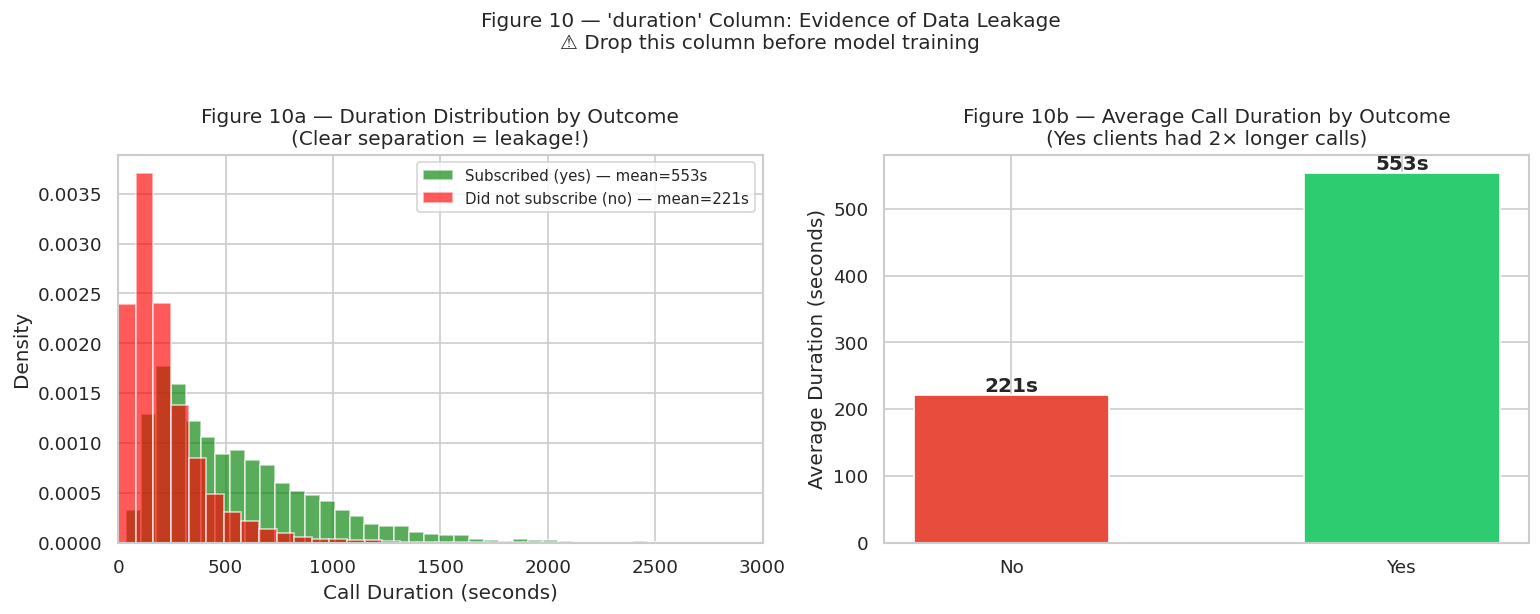


📋 OTHER FEATURES — LEAKAGE ASSESSMENT:
   duration           🚨 HIGH LEAKAGE         Only known after call — MUST DROP
   pdays              ✅ Safe                 Days since last contact — known before calling
   previous           ✅ Safe                 Prior contacts — historical, known upfront
   poutcome           ✅ Safe                 Prior campaign outcome — known before calling
   emp.var.rate       ✅ Safe                 Public macro indicator — available before call
   nr.employed        ✅ Safe                 Public macro indicator — available before call


In [ ]:
#
# WHAT IS DATA LEAKAGE? (Very important concept!)
# Data leakage happens when a feature in your training data contains
# information that would NOT be available at the time of prediction.
#
# ANALOGY:
# Imagine training a model to predict exam scores. If you include
# "did the student pass?" as an input feature, the model will be
# perfect — but completely useless! You already know the answer.
#
# THE 'duration' PROBLEM IN THIS DATASET:
# 'duration' = how long (in seconds) the phone call lasted.
# Problem: You only know this AFTER the call ends.
#          If the call lasted a long time → client was interested → likely "yes"
#          If the call was short → client hung up quickly → likely "no"
# The dataset authors themselves note: "this input should be discarded
# if the intention is to have a realistic predictive model."
#
# RESULT: Including 'duration' artificially inflates model performance.
# The model learns "long calls = yes" which is true historically but
# USELESS because you can't know call length before making the call.

print("\n" + "=" * 65)
print("  SECTION 11 — DATA LEAKAGE ANALYSIS (Q2)")
print("=" * 65)

print("\n🚨 DATA LEAKAGE IDENTIFIED: 'duration' column")
print("─" * 55)
print("   • 'duration' = call length in seconds")
print("   • Known ONLY after the call ends — outcome already determined")
print("   • Including it is like 'cheating' — model learns from the answer")
print("   • MUST BE DROPPED before any model training")

# Show the correlation
dur_corr = df_enc[['duration', 'y_bin']].corr().loc['duration', 'y_bin']
print(f"\n   Pearson r(duration, y_bin) = {dur_corr:.4f}")
print(f"   → {'Strong leakage' if abs(dur_corr) > 0.3 else 'Detectable'} correlation with target")

# Visualise the leakage
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel 1: Distribution of call duration by outcome
dur_yes = df.loc[df['y'] == 'yes', 'duration']
dur_no  = df.loc[df['y'] == 'no',  'duration']
axes[0].hist(dur_yes, bins=60, alpha=0.65, color='green',
             label=f'Subscribed (yes) — mean={dur_yes.mean():.0f}s', density=True)
axes[0].hist(dur_no,  bins=60, alpha=0.65, color='red',
             label=f'Did not subscribe (no) — mean={dur_no.mean():.0f}s', density=True)
axes[0].set_xlabel("Call Duration (seconds)")
axes[0].set_ylabel("Density")
axes[0].set_title("Figure 10a — Duration Distribution by Outcome\n(Clear separation = leakage!)")
axes[0].legend(fontsize=9)
axes[0].set_xlim(0, 3000)

# Panel 2: Average duration by outcome
means = {'No': dur_no.mean(), 'Yes': dur_yes.mean()}
colors_b = ['#e74c3c', '#2ecc71']
bars = axes[1].bar(means.keys(), means.values(), color=colors_b, edgecolor='white', width=0.5)
axes[1].set_title("Figure 10b — Average Call Duration by Outcome\n(Yes clients had 2× longer calls)")
axes[1].set_ylabel("Average Duration (seconds)")
for bar, (k, v) in zip(bars, means.items()):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 v + 5, f'{v:.0f}s', ha='center', fontweight='bold', fontsize=12)

plt.suptitle("Figure 10 — 'duration' Column: Evidence of Data Leakage\n"
             "⚠️ Drop this column before model training", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("/tmp/real_fig10_duration_leakage.png", dpi=120, bbox_inches='tight')
plt.show()

print("\n📋 OTHER FEATURES — LEAKAGE ASSESSMENT:")
leakage_table = [
    ("duration",       "🚨 HIGH LEAKAGE",  "Only known after call — MUST DROP"),
    ("pdays",          "✅ Safe",           "Days since last contact — known before calling"),
    ("previous",       "✅ Safe",           "Prior contacts — historical, known upfront"),
    ("poutcome",       "✅ Safe",           "Prior campaign outcome — known before calling"),
    ("emp.var.rate",   "✅ Safe",           "Public macro indicator — available before call"),
    ("nr.employed",    "✅ Safe",           "Public macro indicator — available before call"),
]
for feat, risk, reason in leakage_table:
    print(f"   {feat:<18} {risk:<22} {reason}")


---
## Cell 14: FEATURE ENGINEERING (Q10)



  SECTION 12 — FEATURE ENGINEERING & CLEANING (Q10)

[Step 1] ✅ Dropped 'duration' (data leakage)
         Columns remaining: 20

[Step 2] ✅ Removed 1784 duplicate rows
         Rows remaining: 39,404

[Step 3] Replacing 'unknown' strings with NaN:
         'job': replaced 325 'unknown' values → NaN
         'marital': replaced 79 'unknown' values → NaN
         'education': replaced 1,686 'unknown' values → NaN
         'default': replaced 8,266 'unknown' values → NaN
         'housing': replaced 980 'unknown' values → NaN
         'loan': replaced 980 'unknown' values → NaN

[Step 4] ✅ Created 'previously_contacted' from 'pdays':
         1,514 clients were previously contacted (3.8%)
         37,890 clients were NEVER previously contacted (96.2%)

[Step 5] ✅ Created 'age_group' bins from 'age':
age_group
Under 25     1603
25-35       14046
35-50       16777
50-65        6372
Over 65       606

[Step 6] ✅ Created 'econ_pressure' = euribor3m × emp.var.rate
         Range: -3.73 to 6.

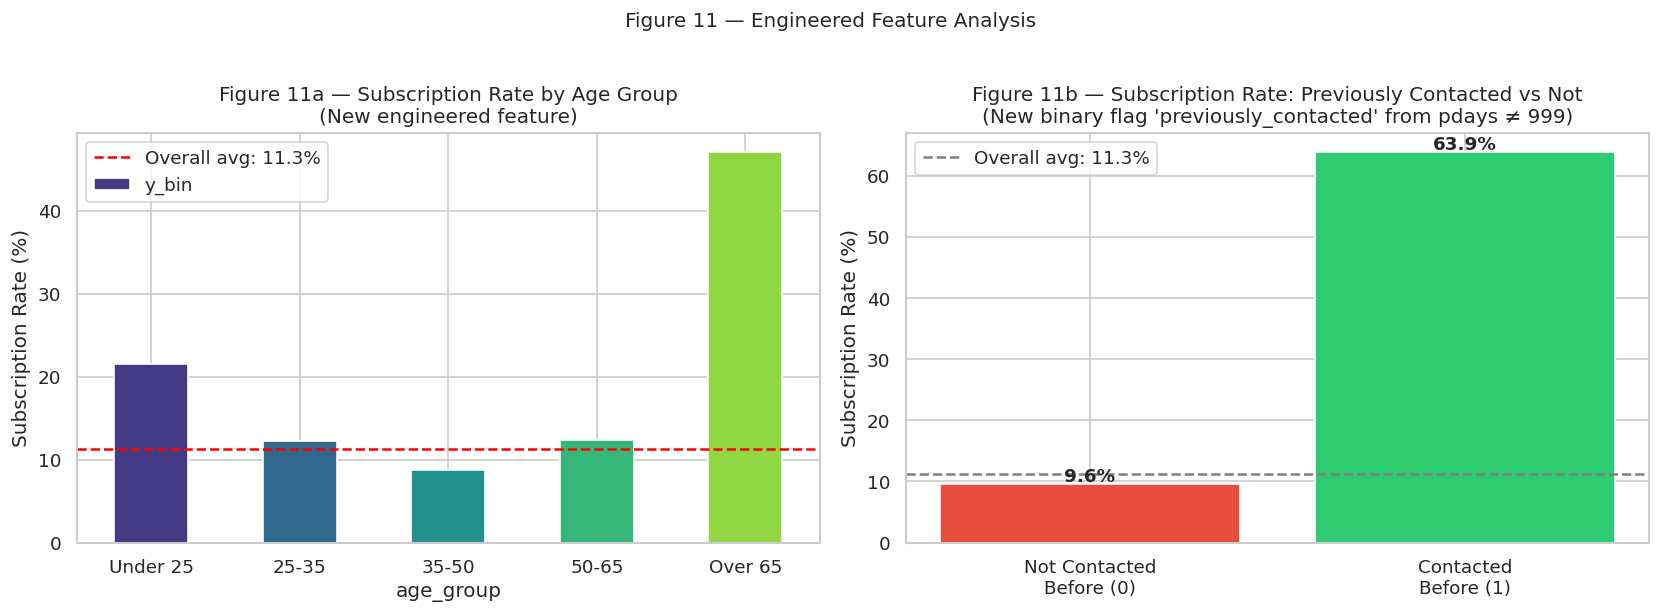

In [ ]:
# ══════════════════════════════════════════════════════════════════════
# CELL 14 — FEATURE ENGINEERING (Q10)
# ══════════════════════════════════════════════════════════════════════
#
# WHAT IS FEATURE ENGINEERING?
# Feature engineering means improving or transforming your data to help
# the ML model learn better. It involves:
#
# 1. DROPPING bad features (like data leakage columns)
# 2. FIXING missing values (imputation)
# 3. CREATING new features from existing ones
# 4. ENCODING categories (converting text to numbers for ML algorithms)
# 5. HANDLING outliers (capping extreme values)
#
# Think of it like prepping ingredients before cooking:
# You wash vegetables (clean data), chop them (transform),
# and maybe combine some to make a sauce (create new features).

print("\n" + "=" * 65)
print("  SECTION 12 — FEATURE ENGINEERING & CLEANING (Q10)")
print("=" * 65)

# Make a clean copy — always work on a copy, never modify the original
df_clean = df.copy()

# ── STEP 1: Drop data leakage feature ──────────────────────────────
df_clean.drop(columns=['duration'], inplace=True)
# inplace=True → modifies df_clean directly (instead of returning a new df)
print(f"\n[Step 1] ✅ Dropped 'duration' (data leakage)")
print(f"         Columns remaining: {df_clean.shape[1]}")

# ── STEP 2: Drop duplicates ─────────────────────────────────────────
before = len(df_clean)
df_clean.drop_duplicates(inplace=True)
after = len(df_clean)
print(f"\n[Step 2] ✅ Removed {before - after} duplicate rows")
print(f"         Rows remaining: {after:,}")

# ── STEP 3: Replace "unknown" strings with NaN ──────────────────────
# NaN is Python's official "missing value" marker.
# Many sklearn imputers and models handle NaN, but not the string "unknown".
# So we replace "unknown" → NaN so tools can detect and handle them.
print(f"\n[Step 3] Replacing 'unknown' strings with NaN:")
for col in categorical_cols:
    if col == 'y':
        continue  # Don't modify the target variable
    count = (df_clean[col] == 'unknown').sum()
    if count > 0:
        df_clean[col] = df_clean[col].replace('unknown', np.nan)
        print(f"         '{col}': replaced {count:,} 'unknown' values → NaN")

# ── STEP 4: Create new feature — "previously_contacted" ─────────────
# WHY THIS NAME?
# 'previously_contacted' is clearer than 'was_contacted_before' because
# "previously" directly implies prior to the current campaign — matching
# the dataset's own language (see column 'previous' and 'pdays').
#
# The 'pdays' column uses 999 to mean "never contacted before this campaign"
# We convert this into a simple 0/1 binary flag:
#   0 = client was NEVER contacted in a prior campaign
#   1 = client WAS contacted in a prior campaign
df_clean['previously_contacted'] = (df_clean['pdays'] != 999).astype(int)
# (df_clean['pdays'] != 999) → True if pdays is NOT 999 → was previously contacted
# .astype(int)               → True→1, False→0
n_prev = df_clean['previously_contacted'].sum()
print(f"\n[Step 4] ✅ Created 'previously_contacted' from 'pdays':")
print(f"         {n_prev:,} clients were previously contacted ({n_prev/len(df_clean)*100:.1f}%)")
print(f"         {len(df_clean)-n_prev:,} clients were NEVER previously contacted ({(len(df_clean)-n_prev)/len(df_clean)*100:.1f}%)")

# ── STEP 5: Create age group bins ───────────────────────────────────
# WHY BIN AGE?
# Raw age (17 to 98) has too many unique values for a model to learn from easily.
# Grouping into brackets (bins) captures meaningful life stages:
#   Under 25 = young, likely less savings
#   25-35    = early career
#   35-50    = peak earning years
#   50-65    = pre-retirement, more savings
#   Over 65  = retired, fixed income
# pd.cut() assigns each age value to its corresponding bin label.
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[0, 25, 35, 50, 65, 100],
    labels=['Under 25', '25-35', '35-50', '50-65', 'Over 65']
)
print(f"\n[Step 5] ✅ Created 'age_group' bins from 'age':")
print(df_clean['age_group'].value_counts().sort_index().to_string())

# ── STEP 6: Create economic pressure index ──────────────────────────
# WHY COMBINE euribor3m AND emp.var.rate?
# These two columns are highly correlated (r=0.972) — they both measure
# economic conditions. Instead of keeping both (redundant), we combine
# them into ONE new feature that captures their joint effect.
#
# econ_pressure = euribor3m × emp.var.rate
# High values = strong economy (high rates + high employment)
# Low/negative values = weak economy (low rates + contracting employment)
# This single feature replaces two correlated ones — reducing redundancy.
df_clean['econ_pressure'] = df_clean['euribor3m'] * df_clean['emp.var.rate']
print(f"\n[Step 6] ✅ Created 'econ_pressure' = euribor3m × emp.var.rate")
print(f"         Range: {df_clean['econ_pressure'].min():.2f} to {df_clean['econ_pressure'].max():.2f}")

# ── STEP 7: Drop the three raw macroeconomic columns ────────────────
# WHY DROP THEM NOW?
# euribor3m, nr.employed, and emp.var.rate are ALL highly correlated:
#   euribor3m  ↔ nr.employed  : r = 0.945
#   euribor3m  ↔ emp.var.rate : r = 0.972
#   nr.employed ↔ emp.var.rate: r = 0.907
#
# We already captured their combined economic signal in 'econ_pressure'.
# Keeping all three RAW columns alongside econ_pressure would be redundant
# and could confuse the model. So we drop them AFTER creating econ_pressure.
#
# IMPORTANT: We drop AFTER Step 6 — not before — because we needed
# euribor3m and emp.var.rate to CREATE econ_pressure first!
df_clean.drop(columns=['euribor3m', 'emp.var.rate', 'nr.employed'], inplace=True)
print(f"\n[Step 7] ✅ Dropped 'euribor3m', 'emp.var.rate', 'nr.employed'")
print(f"         Reason: All replaced by the engineered 'econ_pressure' feature")
print(f"         Columns remaining: {df_clean.shape[1]}")

# ── Final summary ────────────────────────────────────────────────────
df_clean['y_bin'] = (df_clean['y'] == 'yes').astype(int)
print(f"\n{'─'*55}")
print(f"FINAL CLEANED DATASET: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")

# Visualise engineered features
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age group subscription rates
age_sub = (df_clean.groupby('age_group', observed=True)['y_bin']
           .mean() * 100).sort_index()
age_sub.plot(kind='bar', ax=axes[0],
             color=sns.color_palette("viridis", len(age_sub)),
             edgecolor='white')
axes[0].axhline(y=pct_yes, color='red', linestyle='--', lw=1.5,
                label=f'Overall avg: {pct_yes:.1f}%')
axes[0].set_title("Figure 11a — Subscription Rate by Age Group\n(New engineered feature)")
axes[0].set_ylabel("Subscription Rate (%)")
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend()

# Previously contacted vs not
prev_sub = df_clean.groupby('previously_contacted')['y_bin'].mean() * 100
prev_sub.index = ['Not Contacted\nBefore (0)', 'Contacted\nBefore (1)']
bars = axes[1].bar(prev_sub.index, prev_sub.values,
                   color=['#e74c3c', '#2ecc71'], edgecolor='white')
axes[1].axhline(y=pct_yes, color='grey', linestyle='--', lw=1.5,
                label=f'Overall avg: {pct_yes:.1f}%')
axes[1].set_title("Figure 11b — Subscription Rate: Previously Contacted vs Not\n"
                  "(New binary flag 'previously_contacted' from pdays ≠ 999)")
axes[1].set_ylabel("Subscription Rate (%)")
axes[1].legend()
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.4,
                 f'{bar.get_height():.1f}%',
                 ha='center', fontweight='bold', fontsize=11)

plt.suptitle("Figure 11 — Engineered Feature Analysis", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("/tmp/real_fig11_engineered_features.png", dpi=120, bbox_inches='tight')
plt.show()


---
## Cell 15: FINAL SUMMARY & RECOMMENDATIONS (Q10 continued)



  SECTION 12 — FEATURE ENGINEERING & CLEANING (Q10)

[Step 1] ✅ Dropped 'duration' (data leakage)
         Columns remaining: 20

[Step 2] ✅ Removed 1784 duplicate rows
         Rows remaining: 39,404

[Step 3] Replacing 'unknown' strings with NaN:
         'job': replaced 325 'unknown' values → NaN
         'marital': replaced 79 'unknown' values → NaN
         'education': replaced 1,686 'unknown' values → NaN
         'default': replaced 8,266 'unknown' values → NaN
         'housing': replaced 980 'unknown' values → NaN
         'loan': replaced 980 'unknown' values → NaN

[Step 4] ✅ Created 'previously_contacted' from 'pdays':
         1,514 clients were previously contacted (3.8%)
         37,890 clients were NEVER previously contacted (96.2%)

[Step 5] ✅ Created 'age_group' bins from 'age':
age_group
Under 25     1603
25-35       14046
35-50       16777
50-65        6372
Over 65       606

[Step 6] ✅ Created 'econ_pressure' = euribor3m × emp.var.rate
         Range: -3.73 to 6.

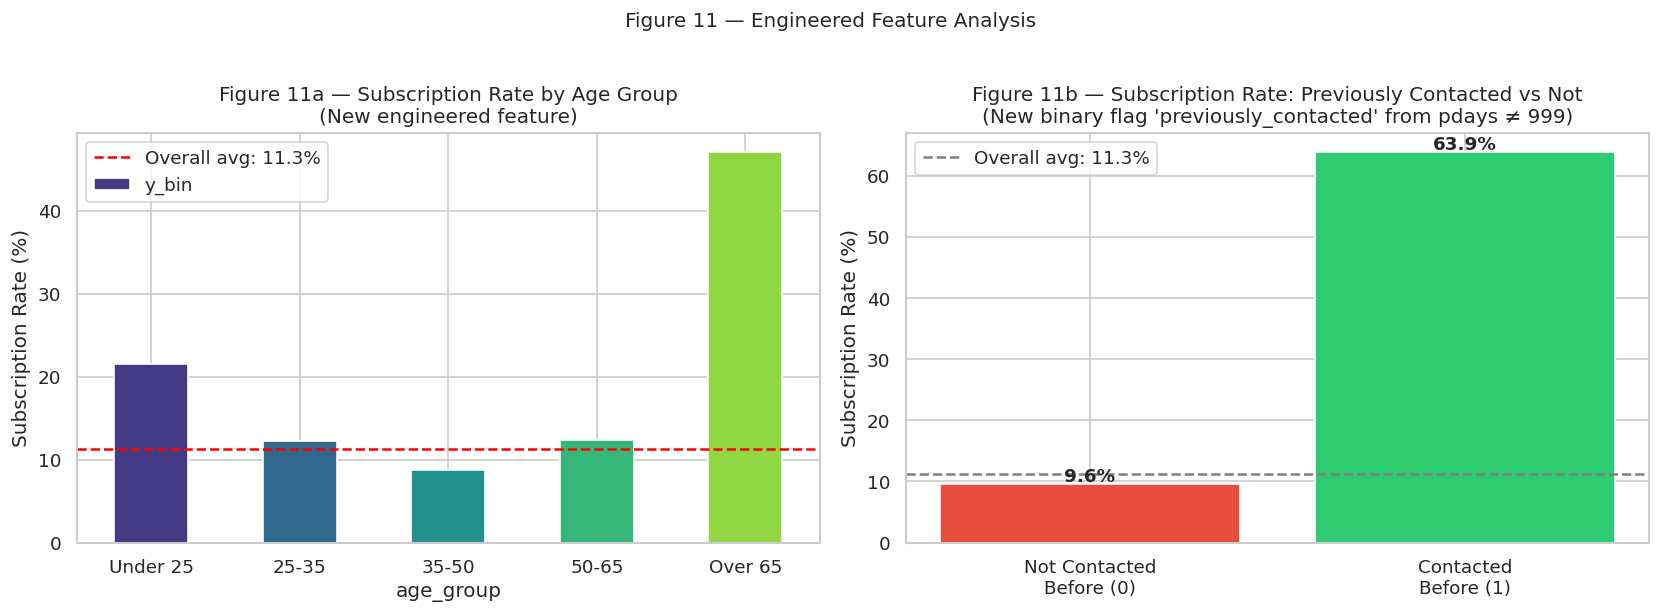

In [ ]:
# ══════════════════════════════════════════════════════════════════════
# CELL 14 — FEATURE ENGINEERING (Q10)
# ══════════════════════════════════════════════════════════════════════
#
# WHAT IS FEATURE ENGINEERING?
# Feature engineering means improving or transforming your data to help
# the ML model learn better. It involves:
#
# 1. DROPPING bad features (like data leakage columns)
# 2. FIXING missing values (imputation)
# 3. CREATING new features from existing ones
# 4. ENCODING categories (converting text to numbers for ML algorithms)
# 5. HANDLING outliers (capping extreme values)
#
# Think of it like prepping ingredients before cooking:
# You wash vegetables (clean data), chop them (transform),
# and maybe combine some to make a sauce (create new features).

print("\n" + "=" * 65)
print("  SECTION 12 — FEATURE ENGINEERING & CLEANING (Q10)")
print("=" * 65)

# Make a clean copy — always work on a copy, never modify the original
df_clean = df.copy()

# ── STEP 1: Drop data leakage feature ──────────────────────────────
df_clean.drop(columns=['duration'], inplace=True)
# inplace=True → modifies df_clean directly (instead of returning a new df)
print(f"\n[Step 1] ✅ Dropped 'duration' (data leakage)")
print(f"         Columns remaining: {df_clean.shape[1]}")

# ── STEP 2: Drop duplicates ─────────────────────────────────────────
before = len(df_clean)
df_clean.drop_duplicates(inplace=True)
after = len(df_clean)
print(f"\n[Step 2] ✅ Removed {before - after} duplicate rows")
print(f"         Rows remaining: {after:,}")

# ── STEP 3: Replace "unknown" strings with NaN ──────────────────────
# NaN is Python's official "missing value" marker.
# Many sklearn imputers and models handle NaN, but not the string "unknown".
# So we replace "unknown" → NaN so tools can detect and handle them.
print(f"\n[Step 3] Replacing 'unknown' strings with NaN:")
for col in categorical_cols:
    if col == 'y':
        continue  # Don't modify the target variable
    count = (df_clean[col] == 'unknown').sum()
    if count > 0:
        df_clean[col] = df_clean[col].replace('unknown', np.nan)
        print(f"         '{col}': replaced {count:,} 'unknown' values → NaN")

# ── STEP 4: Create new feature — "previously_contacted" ─────────────
# WHY THIS NAME?
# 'previously_contacted' is clearer than 'was_contacted_before' because
# "previously" directly implies prior to the current campaign — matching
# the dataset's own language (see column 'previous' and 'pdays').
#
# The 'pdays' column uses 999 to mean "never contacted before this campaign"
# We convert this into a simple 0/1 binary flag:
#   0 = client was NEVER contacted in a prior campaign
#   1 = client WAS contacted in a prior campaign
df_clean['previously_contacted'] = (df_clean['pdays'] != 999).astype(int)
# (df_clean['pdays'] != 999) → True if pdays is NOT 999 → was previously contacted
# .astype(int)               → True→1, False→0
n_prev = df_clean['previously_contacted'].sum()
print(f"\n[Step 4] ✅ Created 'previously_contacted' from 'pdays':")
print(f"         {n_prev:,} clients were previously contacted ({n_prev/len(df_clean)*100:.1f}%)")
print(f"         {len(df_clean)-n_prev:,} clients were NEVER previously contacted ({(len(df_clean)-n_prev)/len(df_clean)*100:.1f}%)")

# ── STEP 5: Create age group bins ───────────────────────────────────
# WHY BIN AGE?
# Raw age (17 to 98) has too many unique values for a model to learn from easily.
# Grouping into brackets (bins) captures meaningful life stages:
#   Under 25 = young, likely less savings
#   25-35    = early career
#   35-50    = peak earning years
#   50-65    = pre-retirement, more savings
#   Over 65  = retired, fixed income
# pd.cut() assigns each age value to its corresponding bin label.
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[0, 25, 35, 50, 65, 100],
    labels=['Under 25', '25-35', '35-50', '50-65', 'Over 65']
)
print(f"\n[Step 5] ✅ Created 'age_group' bins from 'age':")
print(df_clean['age_group'].value_counts().sort_index().to_string())

# ── STEP 6: Create economic pressure index ──────────────────────────
# WHY COMBINE euribor3m AND emp.var.rate?
# These two columns are highly correlated (r=0.972) — they both measure
# economic conditions. Instead of keeping both (redundant), we combine
# them into ONE new feature that captures their joint effect.
#
# econ_pressure = euribor3m × emp.var.rate
# High values = strong economy (high rates + high employment)
# Low/negative values = weak economy (low rates + contracting employment)
# This single feature replaces two correlated ones — reducing redundancy.
df_clean['econ_pressure'] = df_clean['euribor3m'] * df_clean['emp.var.rate']
print(f"\n[Step 6] ✅ Created 'econ_pressure' = euribor3m × emp.var.rate")
print(f"         Range: {df_clean['econ_pressure'].min():.2f} to {df_clean['econ_pressure'].max():.2f}")

# ── STEP 7: Drop the three raw macroeconomic columns ────────────────
# WHY DROP THEM NOW?
# euribor3m, nr.employed, and emp.var.rate are ALL highly correlated:
#   euribor3m  ↔ nr.employed  : r = 0.945
#   euribor3m  ↔ emp.var.rate : r = 0.972
#   nr.employed ↔ emp.var.rate: r = 0.907
#
# We already captured their combined economic signal in 'econ_pressure'.
# Keeping all three RAW columns alongside econ_pressure would be redundant
# and could confuse the model. So we drop them AFTER creating econ_pressure.
#
# IMPORTANT: We drop AFTER Step 6 — not before — because we needed
# euribor3m and emp.var.rate to CREATE econ_pressure first!
df_clean.drop(columns=['euribor3m', 'emp.var.rate', 'nr.employed'], inplace=True)
print(f"\n[Step 7] ✅ Dropped 'euribor3m', 'emp.var.rate', 'nr.employed'")
print(f"         Reason: All replaced by the engineered 'econ_pressure' feature")
print(f"         Columns remaining: {df_clean.shape[1]}")

# ── Final summary ────────────────────────────────────────────────────
df_clean['y_bin'] = (df_clean['y'] == 'yes').astype(int)
print(f"\n{'─'*55}")
print(f"FINAL CLEANED DATASET: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")

# Visualise engineered features
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age group subscription rates
age_sub = (df_clean.groupby('age_group', observed=True)['y_bin']
           .mean() * 100).sort_index()
age_sub.plot(kind='bar', ax=axes[0],
             color=sns.color_palette("viridis", len(age_sub)),
             edgecolor='white')
axes[0].axhline(y=pct_yes, color='red', linestyle='--', lw=1.5,
                label=f'Overall avg: {pct_yes:.1f}%')
axes[0].set_title("Figure 11a — Subscription Rate by Age Group\n(New engineered feature)")
axes[0].set_ylabel("Subscription Rate (%)")
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend()

# Previously contacted vs not
prev_sub = df_clean.groupby('previously_contacted')['y_bin'].mean() * 100
prev_sub.index = ['Not Contacted\nBefore (0)', 'Contacted\nBefore (1)']
bars = axes[1].bar(prev_sub.index, prev_sub.values,
                   color=['#e74c3c', '#2ecc71'], edgecolor='white')
axes[1].axhline(y=pct_yes, color='grey', linestyle='--', lw=1.5,
                label=f'Overall avg: {pct_yes:.1f}%')
axes[1].set_title("Figure 11b — Subscription Rate: Previously Contacted vs Not\n"
                  "(New binary flag 'previously_contacted' from pdays ≠ 999)")
axes[1].set_ylabel("Subscription Rate (%)")
axes[1].legend()
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.4,
                 f'{bar.get_height():.1f}%',
                 ha='center', fontweight='bold', fontsize=11)

plt.suptitle("Figure 11 — Engineered Feature Analysis", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("/tmp/real_fig11_engineered_features.png", dpi=120, bbox_inches='tight')
plt.show()
